In [1]:
# ============================================================
# Notebook 10 — FINAL EXPLORATORY SIGNAL ANALYSIS
# Cell 1
#
# Restore Notebook 06 + Notebook 09 artifacts
# and freeze the final exploratory protocol.
#
# QUESTION:
# Do the same causal inference-time signals become more
# informative about INT4 page sensitivity at Qwen2.5-3B?
#
# Notebook 09 remains the confirmatory cross-model experiment.
# Notebook 10 is explicitly EXPLORATORY.
#
# NO Notebook 11.
# ============================================================

from pathlib import Path
import json
import zipfile
import shutil
import random
import sys

import numpy as np
import pandas as pd
import torch
import sklearn
import transformers


# ============================================================
# 1. Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 2. Environment
# ============================================================

print("Notebook 10 environment")
print("-----------------------")

print(f"Python:       {sys.version.split()[0]}")
print(f"PyTorch:      {torch.__version__}")
print(f"Transformers: {transformers.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

print()
print(f"CUDA available: {torch.cuda.is_available()}")

if not torch.cuda.is_available():
    raise RuntimeError(
        "Notebook 10 requires a CUDA GPU."
    )

print(f"GPU: {torch.cuda.get_device_name(0)}")
print(
    f"GPU memory: "
    f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.2f} GiB"
)


# ============================================================
# 3. Working directories
# ============================================================

NB10_DIR = Path("notebook10_results")

NB10_DIR.mkdir(
    parents=True,
    exist_ok=True
)


NB06_IMPORT_DIR = Path(
    "notebook10_import_nb06"
)

NB09_IMPORT_DIR = Path(
    "notebook10_import_nb09"
)


# ============================================================
# 4. ZIP restore helper
# ============================================================

def locate_zip(
    expected_name,
):

    candidates = [
        Path(expected_name),
        Path("/content") / expected_name,
    ]

    for path in candidates:
        if path.exists():
            return path

    return None


def upload_zip_if_missing(
    expected_name,
):

    path = locate_zip(
        expected_name
    )

    if path is not None:
        return path

    print()
    print(
        f"{expected_name} not found."
    )

    print(
        f"Please upload {expected_name}"
    )

    from google.colab import files

    uploaded = files.upload()

    uploaded_names = list(
        uploaded.keys()
    )

    exact = [
        name
        for name in uploaded_names
        if Path(name).name
        == expected_name
    ]

    if exact:
        return Path(
            exact[0]
        )

    zip_files = [
        name
        for name in uploaded_names
        if name.lower().endswith(".zip")
    ]

    if not zip_files:
        raise FileNotFoundError(
            f"No ZIP uploaded for {expected_name}"
        )

    print(
        f"Warning: exact filename not found; "
        f"using {zip_files[0]}"
    )

    return Path(
        zip_files[0]
    )


def restore_zip(
    zip_path,
    destination,
):

    if destination.exists():
        shutil.rmtree(
            destination
        )

    destination.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(
        zip_path,
        "r"
    ) as zf:

        zf.extractall(
            destination
        )


# ============================================================
# 5. Restore Notebook 09
# ============================================================

NB09_ZIP = locate_zip(
    "notebook09_final_results.zip"
)


# If Cell 8 was run in this same runtime, the folder itself
# may already exist even if the ZIP is absent.
if Path(
    "notebook09_results"
).exists():

    if NB09_IMPORT_DIR.exists():
        shutil.rmtree(
            NB09_IMPORT_DIR
        )

    shutil.copytree(
        "notebook09_results",
        NB09_IMPORT_DIR
    )

    print()
    print(
        "Notebook 09 restored from current runtime directory."
    )

else:

    NB09_ZIP = upload_zip_if_missing(
        "notebook09_final_results.zip"
    )

    restore_zip(
        NB09_ZIP,
        NB09_IMPORT_DIR
    )

    print()
    print(
        f"Notebook 09 restored from: {NB09_ZIP}"
    )


# ============================================================
# 6. Restore Notebook 06
# ============================================================

NB06_ZIP = upload_zip_if_missing(
    "notebook06_results.zip"
)


restore_zip(
    NB06_ZIP,
    NB06_IMPORT_DIR
)


print(
    f"Notebook 06 restored from: {NB06_ZIP}"
)


# ============================================================
# 7. Generic recursive file locator
# ============================================================

def find_file(
    root,
    filename,
    required=True,
):

    matches = list(
        root.rglob(
            filename
        )
    )

    if len(matches) == 0:

        if required:
            raise FileNotFoundError(
                f"Could not find {filename} "
                f"under {root}"
            )

        return None


    if len(matches) > 1:

        print(
            f"Warning: multiple matches for "
            f"{filename}; using {matches[0]}"
        )


    return matches[0]


# ============================================================
# 8. Locate key Notebook 06 artifacts
# ============================================================

NB06_COMBINED_PATH = find_file(
    NB06_IMPORT_DIR,
    "combined_page_features_and_oracle.csv",
)


NB06_DELAYED_PATH = find_file(
    NB06_IMPORT_DIR,
    "delayed_attention_features.csv",
)


NB06_OOF_PATH = find_file(
    NB06_IMPORT_DIR,
    "best_classifier_oof_scores.csv",
    required=False,
)


nb06_combined_df = pd.read_csv(
    NB06_COMBINED_PATH
)


nb06_delayed_df = pd.read_csv(
    NB06_DELAYED_PATH
)


print()
print("Notebook 06 artifacts")
print("---------------------")

print(
    f"Combined features: "
    f"{NB06_COMBINED_PATH}"
)

print(
    f"Delayed features:  "
    f"{NB06_DELAYED_PATH}"
)

print(
    f"Combined rows:     "
    f"{len(nb06_combined_df)}"
)

print(
    f"Delayed rows:      "
    f"{len(nb06_delayed_df)}"
)


# ============================================================
# 9. IMPORTANT:
# Inspect original Notebook 06 columns.
#
# We will use this output to reproduce the original signal
# family exactly, instead of inventing new features.
# ============================================================

print()
print(
    "Notebook 06 combined-feature columns"
)

print(
    "------------------------------------"
)

for i, col in enumerate(
    nb06_combined_df.columns,
    start=1,
):
    print(
        f"{i:02d}. {col}"
    )


print()
print(
    "Notebook 06 delayed-attention columns"
)

print(
    "-------------------------------------"
)

for i, col in enumerate(
    nb06_delayed_df.columns,
    start=1,
):
    print(
        f"{i:02d}. {col}"
    )


# ============================================================
# 10. Locate key Notebook 09 artifacts
# ============================================================

NB09_REF_ORACLE_PATH = find_file(
    NB09_IMPORT_DIR,
    "qwen3b_reference_lifetime_oracle.csv",
)


NB09_REF_TRAINING_PATH = find_file(
    NB09_IMPORT_DIR,
    "qwen3b_reference_risk_training.csv",
)


NB09_UNSEEN_FEATURE_PATH = find_file(
    NB09_IMPORT_DIR,
    "qwen3b_unseen_frozen_features.csv",
)


NB09_UNSEEN3_ORACLE_PATH = find_file(
    NB09_IMPORT_DIR,
    "qwen3b_unseen3_lifetime_oracle.csv",
)


NB09_FINAL_JSON_PATH = find_file(
    NB09_IMPORT_DIR,
    "notebook09_final_conclusion.json",
    required=False,
)


nb09_reference_oracle_df = pd.read_csv(
    NB09_REF_ORACLE_PATH
)


nb09_reference_training_df = pd.read_csv(
    NB09_REF_TRAINING_PATH
)


nb09_unseen_features_df = pd.read_csv(
    NB09_UNSEEN_FEATURE_PATH
)


nb09_unseen3_oracle_df = pd.read_csv(
    NB09_UNSEEN3_ORACLE_PATH
)


print()
print(
    "Notebook 09 oracle artifacts"
)

print(
    "----------------------------"
)

print(
    f"Reference lifetime oracle: "
    f"{NB09_REF_ORACLE_PATH}"
)

print(
    f"Reference risk table:      "
    f"{NB09_REF_TRAINING_PATH}"
)

print(
    f"Unseen features:           "
    f"{NB09_UNSEEN_FEATURE_PATH}"
)

print(
    f"Unseen_3 lifetime oracle:  "
    f"{NB09_UNSEEN3_ORACLE_PATH}"
)


# ============================================================
# 11. Validate the two already-labeled 3B segments
# ============================================================

assert (
    len(
        nb09_reference_oracle_df
    )
    == 115
)

assert (
    len(
        nb09_unseen3_oracle_df
    )
    == 115
)


assert (
    sorted(
        nb09_reference_oracle_df[
            "Page"
        ].astype(int).tolist()
    )
    == list(
        range(
            6,
            121
        )
    )
)


assert (
    sorted(
        nb09_unseen3_oracle_df[
            "Page"
        ].astype(int).tolist()
    )
    == list(
        range(
            6,
            121
        )
    )
)


print()
print(
    "3B oracle validation PASSED:"
)

print(
    "Reference = 115 pages"
)

print(
    "Unseen_3  = 115 pages"
)


# ============================================================
# 12. Freeze Notebook 10 experimental scope
# ============================================================

MODEL_NAME = (
    "Qwen/Qwen2.5-3B"
)

PAGE_SIZE = 16

CACHE_TOKENS = 2048

DECISION_DELAY_PAGES = 2

DECISION_DELAY_TOKENS = (
    DECISION_DELAY_PAGES
    * PAGE_SIZE
)

CANDIDATE_PAGE_START = 6

CANDIDATE_PAGE_END = 120

CANDIDATE_PAGES = list(
    range(
        CANDIDATE_PAGE_START,
        CANDIDATE_PAGE_END + 1
    )
)


# ------------------------------------------------------------
# We use ONLY these two segments because complete
# delay-aligned lifetime-oracle labels already exist.
# ------------------------------------------------------------

DEVELOPMENT_SEGMENT = (
    "Reference"
)

TRANSFER_SEGMENT = (
    "Unseen_3"
)


SEGMENT_STARTS = {

    "Reference":
        0,

    "Unseen_3":
        12288,
}


# ============================================================
# 13. Freeze target
#
# We do NOT return to the old Notebook 05 immediate oracle.
#
# Primary target:
#   affected-token normalized lifetime Delta NLL
#
# Secondary:
#   total lifetime Delta NLL
#
# This matches the final causal 32-token decision timing.
# ============================================================

PRIMARY_TARGET = (
    "Affected_Mean_Delta_NLL"
)

SECONDARY_TARGET = (
    "Delta_Total_NLL"
)


# ============================================================
# 14. Freeze signal families
#
# No new signal families may be introduced after results.
#
# Exact individual column names will be taken from the
# Notebook 06 artifacts printed above wherever possible.
# ============================================================

SIGNAL_FAMILIES = [

    "Position_Recency",

    "Immediate_Attention",

    "Delayed_2Page_Attention",

    "Confidence_Entropy",

    "Quantization_Distortion",

    "Fixed_Combined_NB06_Family",
]


# ============================================================
# 15. Freeze evaluation methodology
# ============================================================

EVALUATION_METRICS = [

    "Spearman correlation with normalized lifetime risk",

    "Spearman correlation with total lifetime risk",

    "top-k and bottom-k oracle overlap",

    "blocked 5-fold OOF ranking correlation on Reference",

    "frozen Reference-to-Unseen_3 transfer correlation",
]


# ------------------------------------------------------------
# We use ONE fixed combined regression family.
#
# Notebook 06's strongest continuous hybrid result used
# Gradient Boosting.
#
# No model sweep in Notebook 10.
# ------------------------------------------------------------

COMBINED_REGRESSOR = (
    "GradientBoostingRegressor"
)

COMBINED_REGRESSOR_RANDOM_STATE = (
    SEED
)


# ============================================================
# 16. Scope freeze
# ============================================================

FORBIDDEN_AFTER_RESULTS = [

    "adding new feature families",

    "changing the 32-token decision delay",

    "changing candidate pages",

    "changing Reference or Unseen_3",

    "building additional lifetime oracles",

    "sweeping multiple regressors to choose the best",

    "tuning hyperparameters based on Unseen_3",

    "changing the target after seeing correlations",

    "evaluating a new policy solely because an exploratory signal looks promising",

    "creating Notebook 11",
]


PREDECLARED_QUESTIONS = [

    (
        "Are attention signals more correlated with "
        "delay-aligned lifetime INT4 sensitivity at 3B "
        "than they were at 1.5B?"
    ),

    (
        "Do confidence / entropy signals become more "
        "informative at 3B?"
    ),

    (
        "Does the 32-token delayed attention signal "
        "outperform immediate attention and simple "
        "position / recency?"
    ),

    (
        "Does V_NRMSE_Max remain a weak intrinsic "
        "sensitivity signal?"
    ),

    (
        "Can the fixed Notebook-06-style combined "
        "Gradient Boosting regressor transfer from the "
        "3B Reference segment to Unseen_3?"
    ),
]


# ============================================================
# 17. Save frozen configuration
# ============================================================

frozen_config = {

    "notebook":
        "Notebook 10 — Final Exploratory Signal Analysis",

    "status":
        "Exploratory",

    "model":
        MODEL_NAME,

    "page_size":
        PAGE_SIZE,

    "cache_tokens":
        CACHE_TOKENS,

    "decision_delay_pages":
        DECISION_DELAY_PAGES,

    "decision_delay_tokens":
        DECISION_DELAY_TOKENS,

    "candidate_page_start":
        CANDIDATE_PAGE_START,

    "candidate_page_end":
        CANDIDATE_PAGE_END,

    "development_segment":
        DEVELOPMENT_SEGMENT,

    "transfer_segment":
        TRANSFER_SEGMENT,

    "segment_starts":
        SEGMENT_STARTS,

    "primary_target":
        PRIMARY_TARGET,

    "secondary_target":
        SECONDARY_TARGET,

    "signal_families":
        SIGNAL_FAMILIES,

    "combined_regressor":
        COMBINED_REGRESSOR,

    "combined_regressor_random_state":
        COMBINED_REGRESSOR_RANDOM_STATE,

    "evaluation_metrics":
        EVALUATION_METRICS,

    "predeclared_questions":
        PREDECLARED_QUESTIONS,

    "forbidden_after_results":
        FORBIDDEN_AFTER_RESULTS,
}


FROZEN_CONFIG_PATH = (
    NB10_DIR
    / "frozen_notebook10_config.json"
)


with open(
    FROZEN_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        frozen_config,
        f,
        indent=2,
    )


# ============================================================
# 18. Final protocol printout
# ============================================================

print()
print(
    "=================================================="
)

print(
    "FROZEN NOTEBOOK 10 PROTOCOL"
)

print(
    "=================================================="
)

print()
print(
    f"Model:              {MODEL_NAME}"
)

print(
    f"Development labels: {DEVELOPMENT_SEGMENT}"
)

print(
    f"Transfer labels:    {TRANSFER_SEGMENT}"
)

print(
    f"Decision delay:     {DECISION_DELAY_TOKENS} tokens"
)

print(
    f"Candidate pages:    "
    f"{CANDIDATE_PAGE_START}-{CANDIDATE_PAGE_END}"
)

print(
    f"Primary target:     {PRIMARY_TARGET}"
)

print(
    f"Combined model:     {COMBINED_REGRESSOR}"
)


print()
print(
    "Signal families"
)

print(
    "---------------"
)

for family in SIGNAL_FAMILIES:
    print(
        f"- {family}"
    )


print()
print(
    "Predeclared questions"
)

print(
    "---------------------"
)

for i, question in enumerate(
    PREDECLARED_QUESTIONS,
    start=1,
):
    print(
        f"{i}. {question}"
    )


print()
print(
    "Scope freeze"
)

print(
    "------------"
)

for item in FORBIDDEN_AFTER_RESULTS:
    print(
        f"- NO {item}"
    )


print()
print(
    "Cell 1 complete."
)

print(
    "Notebook 10 is explicitly exploratory."
)

print(
    "Notebook 09 confirmatory conclusions remain unchanged."
)

print(
    "There will be NO Notebook 11."
)

print()
print(
    f"Frozen config saved to: "
    f"{FROZEN_CONFIG_PATH}"
)

Notebook 10 environment
-----------------------
Python:       3.13.15
PyTorch:      2.11.0+cu128
Transformers: 5.16.1
scikit-learn: 1.6.1

CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GiB

notebook09_final_results.zip not found.
Please upload notebook09_final_results.zip


Saving notebook09_final_results.zip to notebook09_final_results.zip

Notebook 09 restored from: notebook09_final_results.zip

notebook06_results.zip not found.
Please upload notebook06_results.zip


Saving notebook06_results.zip to notebook06_results.zip
Notebook 06 restored from: notebook06_results.zip

Notebook 06 artifacts
---------------------
Combined features: notebook10_import_nb06/combined_page_features_and_oracle.csv
Delayed features:  notebook10_import_nb06/delayed_attention_features.csv
Combined rows:     115
Delayed rows:      459

Notebook 06 combined-feature columns
------------------------------------
01. Page
02. Attn_Self_Mean
03. Attn_Self_Last
04. Attn_Previous_Mean
05. Attn_Previous_Last
06. Attn_SelfPrev_Ratio
07. Attn_Self_LayerStd
08. Attn_Self_LayerMax
09. Attn_Self_Rank
10. Attn_PageEntropy_Mean
11. Attn_PageEntropy_Last
12. Start_Token
13. End_Token
14. Decision_After_Token
15. Visible_Pages
16. Delta_NLL
17. Oracle_Rank
18. Oracle_Percentile
19. Conf_Entropy_Mean
20. Conf_Entropy_Last
21. Conf_Entropy_Max
22. Conf_Top1_Mean
23. Conf_Top1_Last
24. Conf_Margin_Mean
25. Conf_Margin_Last
26. Page_Index
27. Normalized_Position
28. Final_Page_Age
29. Normalize

### Cell 1 — Frozen Final Exploratory Signal Study

Notebook 10 is explicitly an exploratory follow-up to the frozen
cross-model validation in Notebook 09.

The original Notebook 06 artifacts were restored so that the 3B
analysis can reproduce the same signal definitions rather than invent
new features after seeing the larger-model results.

The fixed signal families are:

- position / recency,
- immediate attention,
- 32-token delayed attention,
- confidence / entropy,
- quantization distortion,
- the fixed Notebook-06-style combined feature family.

The primary prediction target is the delay-aligned normalized lifetime
INT4 damage (`Affected_Mean_Delta_NLL`), with total lifetime damage as
a secondary ranking target.

Development uses the Qwen2.5-3B Reference segment and final exploratory
transfer uses the already-labeled `Unseen_3` segment.

No new feature families, additional oracle construction, regressor
sweeps, or post-hoc tuning will be performed. Notebook 09 remains the
confirmatory experiment.

In [2]:
# ============================================================
# Notebook 10 — FINAL EXPLORATORY SIGNAL ANALYSIS
# Cell 2
#
# Load Qwen2.5-3B in FP16 eager-attention mode
# + reproduce Reference and Unseen_3 exactly
# + attach the already-existing delay-aligned oracle targets
#
# NO signal-quality result is computed here.
# ============================================================

from pathlib import Path
import gc
import json

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
)

from datasets import load_dataset


# ============================================================
# 1. Clean device state
# ============================================================

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

DEVICE = torch.device("cuda")


# ============================================================
# 2. Load tokenizer
# ============================================================

print("Loading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True,
)

print(
    f"Tokenizer loaded: {MODEL_NAME}"
)


# ============================================================
# 3. Load model
#
# IMPORTANT:
# We use eager attention because Notebook 10 will request
# output_attentions=True.
#
# We START in FP16 only for the numerical-stability diagnostic.
# Cell 3 will determine whether attention analysis must move
# to FP32, as happened in Notebook 06.
# ============================================================

print()
print(
    "Loading Qwen2.5-3B in FP16 with eager attention..."
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    attn_implementation="eager",
    low_cpu_mem_usage=True,
)

model = model.to(
    DEVICE
)

model.eval()

print(
    "Model loaded."
)


# ============================================================
# 4. Architecture verification
# ============================================================

config = model.config

NUM_LAYERS = int(
    config.num_hidden_layers
)

HIDDEN_SIZE = int(
    config.hidden_size
)

NUM_QUERY_HEADS = int(
    config.num_attention_heads
)

NUM_KV_HEADS = int(
    config.num_key_value_heads
)

HEAD_DIM = int(
    getattr(
        config,
        "head_dim",
        HIDDEN_SIZE // NUM_QUERY_HEADS,
    )
)

PARAM_COUNT = sum(
    p.numel()
    for p in model.parameters()
)

MODEL_DTYPE = next(
    model.parameters()
).dtype


print()
print(
    "Qwen2.5-3B architecture"
)

print(
    "-----------------------"
)

print(
    f"Parameters:     {PARAM_COUNT:,}"
)

print(
    f"Layers:         {NUM_LAYERS}"
)

print(
    f"Hidden size:    {HIDDEN_SIZE}"
)

print(
    f"Query heads:    {NUM_QUERY_HEADS}"
)

print(
    f"KV heads:       {NUM_KV_HEADS}"
)

print(
    f"Head dimension: {HEAD_DIM}"
)

print(
    f"Dtype:          {MODEL_DTYPE}"
)


assert NUM_LAYERS == 36
assert HIDDEN_SIZE == 2048
assert NUM_QUERY_HEADS == 16
assert NUM_KV_HEADS == 2
assert HEAD_DIM == 128
assert MODEL_DTYPE == torch.float16

print()
print(
    "Architecture assertions PASSED."
)


# ============================================================
# 5. GPU memory after loading
# ============================================================

allocated_gib = (
    torch.cuda.memory_allocated()
    / 2**30
)

reserved_gib = (
    torch.cuda.memory_reserved()
    / 2**30
)

print()
print(
    "GPU memory after model load"
)

print(
    "---------------------------"
)

print(
    f"Allocated: {allocated_gib:.3f} GiB"
)

print(
    f"Reserved:  {reserved_gib:.3f} GiB"
)


# ============================================================
# 6. Load exact WikiText-2 test stream
# ============================================================

print()
print(
    "Loading WikiText-2..."
)

dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="test",
)

print(
    f"Test rows: {len(dataset)}"
)


# Exact construction used in Notebooks 08/09
full_text = "\n\n".join(
    dataset["text"]
)


encoded = tokenizer(
    full_text,
    add_special_tokens=False,
    return_attention_mask=False,
)


all_token_ids = torch.tensor(
    encoded["input_ids"],
    dtype=torch.long,
)


TOTAL_TOKENS = int(
    all_token_ids.numel()
)


print(
    f"Full token count: {TOTAL_TOKENS:,}"
)


assert TOTAL_TOKENS == 299_078

print(
    "Token-count assertion PASSED."
)


# ============================================================
# 7. Reconstruct ONLY the two labeled 3B segments
#
# Need 2048 cache tokens + one boundary target.
# ============================================================

SEGMENT_TOKEN_LENGTH = (
    CACHE_TOKENS + 1
)


SEGMENT_IDS_CPU = {}


for segment_name, start in (
    SEGMENT_STARTS.items()
):

    end_exclusive = (
        start
        + SEGMENT_TOKEN_LENGTH
    )

    ids = (
        all_token_ids[
            start:end_exclusive
        ]
        .clone()
        .unsqueeze(0)
    )

    assert ids.shape == (
        1,
        SEGMENT_TOKEN_LENGTH,
    )

    SEGMENT_IDS_CPU[
        segment_name
    ] = ids


print()
print(
    "Reconstructed labeled segments"
)

print(
    "------------------------------"
)


for segment_name, start in (
    SEGMENT_STARTS.items()
):

    end_inclusive = (
        start
        + SEGMENT_TOKEN_LENGTH
        - 1
    )

    print(
        f"{segment_name:<9}: "
        f"{start}-{end_inclusive} "
        f"({SEGMENT_TOKEN_LENGTH} tokens)"
    )


# ============================================================
# 8. Build clean oracle target tables
#
# These labels already exist from Notebook 09.
# We are NOT recomputing or changing them.
# ============================================================

reference_target_df = (

    nb09_reference_oracle_df[
        [
            "Page",
            "Remaining_Affected_Targets",
            "Delta_Total_NLL",
            "Affected_Mean_Delta_NLL",
            "Relative_PPL_vs_INT8_pct",
        ]
    ]

    .copy()
)


unseen3_target_df = (

    nb09_unseen3_oracle_df[
        [
            "Page",
            "Remaining_Affected_Targets",
            "Delta_Total_NLL",
            "Affected_Mean_Delta_NLL",
            "Relative_PPL_vs_INT8_pct",
        ]
    ]

    .copy()
)


reference_target_df[
    "Segment"
] = "Reference"


unseen3_target_df[
    "Segment"
] = "Unseen_3"


TARGETS_3B_DF = pd.concat(
    [
        reference_target_df,
        unseen3_target_df,
    ],
    ignore_index=True,
)


# ============================================================
# 9. Validate targets
# ============================================================

for segment_name in [
    "Reference",
    "Unseen_3",
]:

    sub = TARGETS_3B_DF[

        TARGETS_3B_DF[
            "Segment"
        ]
        == segment_name

    ].sort_values(
        "Page"
    )


    assert len(sub) == 115

    assert (
        sub[
            "Page"
        ]
        .astype(int)
        .tolist()
        ==
        CANDIDATE_PAGES
    )

    assert (
        sub[
            PRIMARY_TARGET
        ]
        .notna()
        .all()
    )

    assert (
        sub[
            SECONDARY_TARGET
        ]
        .notna()
        .all()
    )


print()
print(
    "Delay-aligned oracle targets verified."
)


# ============================================================
# 10. Target distribution preview
#
# Descriptive only; these targets were already observed in
# Notebook 09 and do not constitute a new signal result.
# ============================================================

target_summary_rows = []


for segment_name in [
    "Reference",
    "Unseen_3",
]:

    sub = TARGETS_3B_DF[

        TARGETS_3B_DF[
            "Segment"
        ]
        == segment_name

    ]


    target_summary_rows.append({

        "Segment":
            segment_name,

        "NormalizedRisk_Min":
            float(
                sub[
                    PRIMARY_TARGET
                ].min()
            ),

        "NormalizedRisk_Median":
            float(
                sub[
                    PRIMARY_TARGET
                ].median()
            ),

        "NormalizedRisk_Mean":
            float(
                sub[
                    PRIMARY_TARGET
                ].mean()
            ),

        "NormalizedRisk_Max":
            float(
                sub[
                    PRIMARY_TARGET
                ].max()
            ),

        "TotalRisk_Min":
            float(
                sub[
                    SECONDARY_TARGET
                ].min()
            ),

        "TotalRisk_Median":
            float(
                sub[
                    SECONDARY_TARGET
                ].median()
            ),

        "TotalRisk_Mean":
            float(
                sub[
                    SECONDARY_TARGET
                ].mean()
            ),

        "TotalRisk_Max":
            float(
                sub[
                    SECONDARY_TARGET
                ].max()
            ),
    })


target_summary_df = pd.DataFrame(
    target_summary_rows
)


print()
print(
    "Existing 3B oracle-target distributions"
)

print(
    "---------------------------------------"
)


display(
    target_summary_df
)


# ============================================================
# 11. Text previews
# ============================================================

print()
print(
    "Segment previews"
)

print(
    "----------------"
)


for segment_name in [
    "Reference",
    "Unseen_3",
]:

    preview_ids = (

        SEGMENT_IDS_CPU[
            segment_name
        ][
            0,
            :48
        ]
        .tolist()
    )


    preview = tokenizer.decode(
        preview_ids
    )


    preview = (
        preview
        .replace(
            "\n",
            " "
        )
        .strip()
    )


    if len(preview) > 160:
        preview = (
            preview[:160]
            + "..."
        )


    print(
        f"{segment_name:<9}: "
        f"{preview}"
    )


# ============================================================
# 12. Save target/segment preparation artifacts
# ============================================================

TARGET_PATH = (
    NB10_DIR
    / "qwen3b_existing_oracle_targets.csv"
)


TARGET_SUMMARY_PATH = (
    NB10_DIR
    / "qwen3b_target_distributions.csv"
)


SEGMENT_MANIFEST_PATH = (
    NB10_DIR
    / "qwen3b_signal_segments.csv"
)


TARGETS_3B_DF.to_csv(
    TARGET_PATH,
    index=False,
)


target_summary_df.to_csv(
    TARGET_SUMMARY_PATH,
    index=False,
)


segment_manifest_df = pd.DataFrame(
    [
        {
            "Segment":
                name,

            "Start_Token":
                start,

            "End_Token_Inclusive":
                start
                + SEGMENT_TOKEN_LENGTH
                - 1,

            "Token_Count":
                SEGMENT_TOKEN_LENGTH,
        }

        for name, start
        in SEGMENT_STARTS.items()
    ]
)


segment_manifest_df.to_csv(
    SEGMENT_MANIFEST_PATH,
    index=False,
)


# ============================================================
# 13. Final state
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 2 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    "Qwen2.5-3B loaded in FP16 eager-attention mode."
)

print(
    "Reference and Unseen_3 reproduced exactly."
)

print(
    "Existing Notebook 09 lifetime-oracle targets attached."
)

print()

print(
    "No new attention/confidence correlation has "
    "been measured yet."
)

print()

print(
    "Cell 3 will test FP16 eager attention for "
    "numerical stability before full signal extraction."
)

Loading tokenizer...


config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Test rows: 4358


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors


Full token count: 299,078
Token-count assertion PASSED.

Reconstructed labeled segments
------------------------------
Reference: 0-2048 (2049 tokens)
Unseen_3 : 12288-14336 (2049 tokens)

Delay-aligned oracle targets verified.

Existing 3B oracle-target distributions
---------------------------------------


,Segment,NormalizedRisk_Min,NormalizedRisk_Median,NormalizedRisk_Mean,NormalizedRisk_Max,TotalRisk_Min,TotalRisk_Median,TotalRisk_Mean,TotalRisk_Max
0,Reference,-0.006473,0.008567,0.047566,1.053379,-4.394475,6.487189,30.627966,303.373062
1,Unseen_3,-0.005359,0.007239,0.020532,0.310414,-1.131518,6.204095,13.656940,204.932448



Segment previews
----------------
Reference: = Robert Boulter =       Robert Boulter is an English film , television and theatre actor . He had a guest @-@ starring role on the television series The Bill i...
Unseen_3 : ) at a speed of 14 knots ( 26 km / h ; 16 mph ) . Ise and Hyūga had three generators of 150 kilowatts ( 200 hp ) capacity

CELL 2 COMPLETE

Qwen2.5-3B loaded in FP16 eager-attention mode.
Reference and Unseen_3 reproduced exactly.
Existing Notebook 09 lifetime-oracle targets attached.

No new attention/confidence correlation has been measured yet.

Cell 3 will test FP16 eager attention for numerical stability before full signal extraction.


In [3]:
# ============================================================
# Notebook 10 — FINAL EXPLORATORY SIGNAL ANALYSIS
# Cell 3
#
# Numerical-stability diagnostic for eager attention.
#
# 1. Test streaming attention in FP16.
# 2. If ANY non-finite attention/logit value appears,
#    discard the FP16 analysis model.
# 3. Reload Qwen2.5-3B in FP32 eager-attention mode.
# 4. Repeat the exact same diagnostic.
#
# No correlation with oracle labels is computed here.
# ============================================================

import gc
import json
import time

import numpy as np
import pandas as pd
import torch

from transformers import (
    AutoModelForCausalLM,
    DynamicCache,
)


# ============================================================
# 1. Fixed diagnostic setup
#
# Test first 4 logical pages = 64 tokens.
# This is enough to exercise:
#   - first-page self attention
#   - cached attention to previous pages
#   - growing key length
#
# We do NOT inspect oracle labels here.
# ============================================================

DIAGNOSTIC_SEGMENT = "Reference"

DIAGNOSTIC_PAGES = 4

DIAGNOSTIC_TOKENS = (
    DIAGNOSTIC_PAGES
    * PAGE_SIZE
)


diagnostic_ids = (
    SEGMENT_IDS_CPU[
        DIAGNOSTIC_SEGMENT
    ][
        :,
        :DIAGNOSTIC_TOKENS
    ]
)


assert diagnostic_ids.shape == (
    1,
    DIAGNOSTIC_TOKENS,
)


print(
    "Attention numerical-stability diagnostic"
)

print(
    "----------------------------------------"
)

print(
    f"Segment:          {DIAGNOSTIC_SEGMENT}"
)

print(
    f"Pages tested:     {DIAGNOSTIC_PAGES}"
)

print(
    f"Tokens tested:    {DIAGNOSTIC_TOKENS}"
)

print(
    f"Initial dtype:    "
    f"{next(model.parameters()).dtype}"
)


# ============================================================
# 2. DynamicCache compatibility helper
# ============================================================

def make_dynamic_cache(
    current_model,
):

    try:

        return DynamicCache(
            config=current_model.config
        )

    except TypeError:

        return DynamicCache()


# ============================================================
# 3. One diagnostic run
# ============================================================

@torch.inference_mode()
def run_attention_stability_diagnostic(
    current_model,
    input_ids,
    label,
):
    """
    Process DIAGNOSTIC_PAGES sequentially with KV caching
    and output_attentions=True.

    Records:
      - logits finiteness
      - per-layer attention finiteness
      - fraction finite
      - attention row-sum behavior
      - tensor shapes

    Does NOT use any oracle labels.
    """

    cache = make_dynamic_cache(
        current_model
    )

    rows = []

    all_logits_finite = True
    all_attention_finite = True

    torch.cuda.synchronize()

    start_time = time.time()


    for page_idx in range(
        DIAGNOSTIC_PAGES
    ):

        start = (
            page_idx
            * PAGE_SIZE
        )

        end = (
            start
            + PAGE_SIZE
        )


        current_ids = (
            input_ids[
                :,
                start:end
            ]
            .to(
                DEVICE
            )
        )


        cache_position = torch.arange(
            start,
            end,
            device=DEVICE,
            dtype=torch.long,
        )


        attention_mask = torch.ones(
            (
                1,
                end,
            ),
            device=DEVICE,
            dtype=torch.long,
        )


        outputs = current_model(
            input_ids=current_ids,
            attention_mask=attention_mask,
            past_key_values=cache,
            use_cache=True,
            cache_position=cache_position,
            output_attentions=True,
            return_dict=True,
        )


        # ----------------------------------------------------
        # Logits diagnostic
        # ----------------------------------------------------

        logits = outputs.logits

        logits_finite_mask = (
            torch.isfinite(
                logits
            )
        )

        logits_fraction_finite = float(
            logits_finite_mask
            .float()
            .mean()
            .item()
        )

        logits_all_finite = bool(
            logits_finite_mask
            .all()
            .item()
        )


        all_logits_finite = (
            all_logits_finite
            and logits_all_finite
        )


        # ----------------------------------------------------
        # Attention diagnostics
        # ----------------------------------------------------

        attentions = outputs.attentions


        assert attentions is not None

        assert len(attentions) == NUM_LAYERS


        for layer_idx, attn in enumerate(
            attentions
        ):

            finite_mask = (
                torch.isfinite(
                    attn
                )
            )


            fraction_finite = float(
                finite_mask
                .float()
                .mean()
                .item()
            )


            layer_all_finite = bool(
                finite_mask
                .all()
                .item()
            )


            all_attention_finite = (
                all_attention_finite
                and layer_all_finite
            )


            # --------------------------------------------
            # Row-sum diagnostic only when fully finite
            # --------------------------------------------

            if layer_all_finite:

                row_sums = (
                    attn.float()
                    .sum(
                        dim=-1
                    )
                )


                row_sum_mean = float(
                    row_sums
                    .mean()
                    .item()
                )


                row_sum_min = float(
                    row_sums
                    .min()
                    .item()
                )


                row_sum_max = float(
                    row_sums
                    .max()
                    .item()
                )

            else:

                row_sum_mean = np.nan
                row_sum_min = np.nan
                row_sum_max = np.nan


            rows.append({

                "Run":
                    label,

                "Model_Dtype":
                    str(
                        next(
                            current_model.parameters()
                        ).dtype
                    ),

                "Page":
                    int(
                        page_idx
                    ),

                "Query_Start":
                    int(
                        start
                    ),

                "Query_End":
                    int(
                        end - 1
                    ),

                "Visible_Tokens":
                    int(
                        end
                    ),

                "Layer":
                    int(
                        layer_idx
                    ),

                "Attention_Shape":
                    str(
                        tuple(
                            attn.shape
                        )
                    ),

                "Attention_All_Finite":
                    layer_all_finite,

                "Attention_Fraction_Finite":
                    fraction_finite,

                "Attention_RowSum_Mean":
                    row_sum_mean,

                "Attention_RowSum_Min":
                    row_sum_min,

                "Attention_RowSum_Max":
                    row_sum_max,

                "Logits_All_Finite":
                    logits_all_finite,

                "Logits_Fraction_Finite":
                    logits_fraction_finite,
            })


        # ----------------------------------------------------
        # Free page outputs aggressively
        # ----------------------------------------------------

        del outputs
        del logits
        del attentions
        del current_ids

        gc.collect()


    torch.cuda.synchronize()


    runtime = (
        time.time()
        - start_time
    )


    df = pd.DataFrame(
        rows
    )


    del cache

    gc.collect()
    torch.cuda.empty_cache()


    return {

        "table":
            df,

        "all_logits_finite":
            bool(
                all_logits_finite
            ),

        "all_attention_finite":
            bool(
                all_attention_finite
            ),

        "fully_stable":
            bool(
                all_logits_finite
                and
                all_attention_finite
            ),

        "runtime_seconds":
            float(
                runtime
            ),
    }


# ============================================================
# 4. Run FP16 diagnostic
# ============================================================

print()
print(
    "Running FP16 eager-attention diagnostic..."
)


gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()


fp16_diag = (
    run_attention_stability_diagnostic(

        current_model=model,

        input_ids=diagnostic_ids,

        label="FP16_Eager",
    )
)


fp16_peak_gib = (
    torch.cuda.max_memory_allocated()
    / 2**30
)


print()
print(
    "FP16 diagnostic"
)

print(
    "---------------"
)

print(
    f"All logits finite:     "
    f"{fp16_diag['all_logits_finite']}"
)

print(
    f"All attention finite:  "
    f"{fp16_diag['all_attention_finite']}"
)

print(
    f"Fully stable:          "
    f"{fp16_diag['fully_stable']}"
)

print(
    f"Runtime:               "
    f"{fp16_diag['runtime_seconds']:.2f} sec"
)

print(
    f"Peak allocated memory: "
    f"{fp16_peak_gib:.3f} GiB"
)


# ============================================================
# 5. Compact FP16 layer/page summary
# ============================================================

fp16_page_summary = (

    fp16_diag[
        "table"
    ]

    .groupby(
        "Page",
        as_index=False,
    )

    .agg(
        Layers_Fully_Finite=(
            "Attention_All_Finite",
            "sum",
        ),

        Min_Attention_Finite_Fraction=(
            "Attention_Fraction_Finite",
            "min",
        ),

        Mean_Attention_Finite_Fraction=(
            "Attention_Fraction_Finite",
            "mean",
        ),

        Logits_All_Finite=(
            "Logits_All_Finite",
            "all",
        ),
    )
)


print()
print(
    "FP16 per-page summary"
)

print(
    "---------------------"
)

display(
    fp16_page_summary
)


# ============================================================
# 6. Decide analysis dtype
#
# This decision is purely numerical:
#
#   if FP16 attention/logits are fully finite -> retain FP16
#
#   otherwise -> reload exact same checkpoint in FP32 eager
#
# No oracle/signal-performance result influences this choice.
# ============================================================

if fp16_diag[
    "fully_stable"
]:

    ATTENTION_ANALYSIS_DTYPE = (
        torch.float16
    )

    ATTENTION_ANALYSIS_MODE = (
        "FP16 eager"
    )

    final_diag = (
        fp16_diag
    )

    print()
    print(
        "FP16 eager attention is numerically stable."
    )

    print(
        "Notebook 10 attention analysis will remain FP16."
    )


else:

    print()
    print(
        "FP16 eager attention is NOT fully finite."
    )

    print(
        "Reloading the identical Qwen2.5-3B checkpoint "
        "in FP32 for attention analysis only..."
    )


    # --------------------------------------------------------
    # Delete FP16 model completely before loading FP32
    # to avoid transient duplication of 3B parameters.
    # --------------------------------------------------------

    del model

    gc.collect()
    torch.cuda.empty_cache()


    print()
    print(
        "GPU memory after deleting FP16 model:"
    )

    print(
        f"{torch.cuda.memory_allocated() / 2**30:.3f} GiB allocated"
    )


    # --------------------------------------------------------
    # Reload in FP32 eager mode
    # --------------------------------------------------------

    model = (
        AutoModelForCausalLM
        .from_pretrained(

            MODEL_NAME,

            dtype=torch.float32,

            attn_implementation="eager",

            low_cpu_mem_usage=True,
        )
    )


    model = model.to(
        DEVICE
    )

    model.eval()


    assert (
        next(
            model.parameters()
        ).dtype
        == torch.float32
    )


    print()
    print(
        "FP32 model loaded."
    )

    print(
        f"Allocated after load: "
        f"{torch.cuda.memory_allocated() / 2**30:.3f} GiB"
    )


    # --------------------------------------------------------
    # Repeat exact diagnostic
    # --------------------------------------------------------

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()


    print()
    print(
        "Running FP32 eager-attention diagnostic..."
    )


    fp32_diag = (
        run_attention_stability_diagnostic(

            current_model=model,

            input_ids=diagnostic_ids,

            label="FP32_Eager",
        )
    )


    fp32_peak_gib = (
        torch.cuda.max_memory_allocated()
        / 2**30
    )


    print()
    print(
        "FP32 diagnostic"
    )

    print(
        "---------------"
    )

    print(
        f"All logits finite:     "
        f"{fp32_diag['all_logits_finite']}"
    )

    print(
        f"All attention finite:  "
        f"{fp32_diag['all_attention_finite']}"
    )

    print(
        f"Fully stable:          "
        f"{fp32_diag['fully_stable']}"
    )

    print(
        f"Runtime:               "
        f"{fp32_diag['runtime_seconds']:.2f} sec"
    )

    print(
        f"Peak allocated memory: "
        f"{fp32_peak_gib:.3f} GiB"
    )


    fp32_page_summary = (

        fp32_diag[
            "table"
        ]

        .groupby(
            "Page",
            as_index=False,
        )

        .agg(
            Layers_Fully_Finite=(
                "Attention_All_Finite",
                "sum",
            ),

            Min_Attention_Finite_Fraction=(
                "Attention_Fraction_Finite",
                "min",
            ),

            Mean_Attention_Finite_Fraction=(
                "Attention_Fraction_Finite",
                "mean",
            ),

            Logits_All_Finite=(
                "Logits_All_Finite",
                "all",
            ),

            Mean_RowSum=(
                "Attention_RowSum_Mean",
                "mean",
            ),

            Min_RowSum=(
                "Attention_RowSum_Min",
                "min",
            ),

            Max_RowSum=(
                "Attention_RowSum_Max",
                "max",
            ),
        )
    )


    print()
    print(
        "FP32 per-page summary"
    )

    print(
        "---------------------"
    )

    display(
        fp32_page_summary
    )


    if not fp32_diag[
        "fully_stable"
    ]:

        raise RuntimeError(
            "FP32 eager attention is also non-finite. "
            "Stop Notebook 10 here rather than using "
            "invalid attention signals."
        )


    ATTENTION_ANALYSIS_DTYPE = (
        torch.float32
    )

    ATTENTION_ANALYSIS_MODE = (
        "FP32 eager"
    )

    final_diag = (
        fp32_diag
    )


# ============================================================
# 7. Final numerical checks
# ============================================================

assert final_diag[
    "fully_stable"
]


final_table = (
    final_diag[
        "table"
    ]
)


# If stable, row sums should be approximately one.
stable_rows = final_table[

    final_table[
        "Attention_All_Finite"
    ]

]


max_rowsum_error = float(

    np.max(

        np.abs(

            stable_rows[
                "Attention_RowSum_Mean"
            ].to_numpy()

            - 1.0
        )
    )
)


print()
print(
    "Final attention-analysis mode"
)

print(
    "-----------------------------"
)

print(
    f"Mode:              "
    f"{ATTENTION_ANALYSIS_MODE}"
)

print(
    f"Model dtype:       "
    f"{next(model.parameters()).dtype}"
)

print(
    f"Max mean row-sum "
    f"error from 1:     "
    f"{max_rowsum_error:.8f}"
)


# ============================================================
# 8. Save diagnostic artifacts
# ============================================================

FP16_DIAG_PATH = (
    NB10_DIR
    / "fp16_eager_attention_diagnostic.csv"
)


fp16_diag[
    "table"
].to_csv(
    FP16_DIAG_PATH,
    index=False,
)


FINAL_DIAG_PATH = (
    NB10_DIR
    / "final_attention_diagnostic.csv"
)


final_table.to_csv(
    FINAL_DIAG_PATH,
    index=False,
)


DIAG_SUMMARY_PATH = (
    NB10_DIR
    / "attention_numerical_stability_summary.json"
)


diag_summary = {

    "diagnostic_segment":
        DIAGNOSTIC_SEGMENT,

    "diagnostic_pages":
        DIAGNOSTIC_PAGES,

    "diagnostic_tokens":
        DIAGNOSTIC_TOKENS,

    "fp16_fully_stable":
        bool(
            fp16_diag[
                "fully_stable"
            ]
        ),

    "final_analysis_mode":
        ATTENTION_ANALYSIS_MODE,

    "final_model_dtype":
        str(
            next(
                model.parameters()
            ).dtype
        ),

    "final_fully_stable":
        bool(
            final_diag[
                "fully_stable"
            ]
        ),

    "max_mean_attention_rowsum_error":
        max_rowsum_error,
}


with open(
    DIAG_SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        diag_summary,
        f,
        indent=2,
    )


# ============================================================
# 9. Final output
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 3 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    f"Attention analysis mode: "
    f"{ATTENTION_ANALYSIS_MODE}"
)

print(
    f"Final dtype: "
    f"{next(model.parameters()).dtype}"
)

print(
    "All diagnostic logits are finite."
)

print(
    "All diagnostic attention tensors are finite."
)

print()

print(
    "This dtype choice was made solely for numerical "
    "stability and does not alter the FP16/INT8/INT4 "
    "cache-quality experiments."
)

print()

print(
    "No correlation with lifetime risk has been "
    "computed yet."
)

print()

print(
    "Cell 4 will extract the frozen Notebook-06-style "
    "immediate attention, 32-token delayed attention, "
    "confidence, and position signals for Reference "
    "and Unseen_3."
)

Attention numerical-stability diagnostic
----------------------------------------
Segment:          Reference
Pages tested:     4
Tokens tested:    64
Initial dtype:    torch.float16

Running FP16 eager-attention diagnostic...

FP16 diagnostic
---------------
All logits finite:     True
All attention finite:  True
Fully stable:          True
Runtime:               3.96 sec
Peak allocated memory: 5.885 GiB

FP16 per-page summary
---------------------


,Page,Layers_Fully_Finite,Min_Attention_Finite_Fraction,Mean_Attention_Finite_Fraction,Logits_All_Finite
0,0,36,1.0,1.0,True
1,1,36,1.0,1.0,True
2,2,36,1.0,1.0,True
3,3,36,1.0,1.0,True



FP16 eager attention is numerically stable.
Notebook 10 attention analysis will remain FP16.

Final attention-analysis mode
-----------------------------
Mode:              FP16 eager
Model dtype:       torch.float16
Max mean row-sum error from 1:     0.00002170

CELL 3 COMPLETE

Attention analysis mode: FP16 eager
Final dtype: torch.float16
All diagnostic logits are finite.
All diagnostic attention tensors are finite.

This dtype choice was made solely for numerical stability and does not alter the FP16/INT8/INT4 cache-quality experiments.

No correlation with lifetime risk has been computed yet.

Cell 4 will extract the frozen Notebook-06-style immediate attention, 32-token delayed attention, confidence, and position signals for Reference and Unseen_3.


### Cell 3 — Attention Numerical-Stability Check

Unlike the earlier Qwen2.5-1.5B attention analysis, Qwen2.5-3B
produced fully finite eager-attention tensors directly in FP16 during
the numerical-stability diagnostic.

Across the first four logical pages:

- all logits were finite,
- all attention entries in all 36 layers were finite,
- the minimum finite fraction was 1.0,
- and the maximum mean attention-row-sum deviation from one was only
  approximately \(2.2\times10^{-5}\).

Therefore Notebook 10 retains FP16 for the attention-analysis path.
This choice is based only on numerical stability and does not modify
the previously completed FP16/INT8/INT4 cache-quality experiments.

The complete 128-page extraction will continue to verify finiteness
online and will stop if any non-finite attention or logits are
encountered.

In [4]:
# ============================================================
# Notebook 10 — FINAL EXPLORATORY SIGNAL ANALYSIS
# Cell 4
#
# Full causal signal extraction on:
#   - Reference
#   - Unseen_3
#
# Extract:
#   1. Immediate attention
#   2. 32-token delayed attention
#   3. Confidence / entropy
#   4. Position / recency
#   5. Existing V_NRMSE_Max from Notebook 09
#
# NO correlation with oracle targets is computed here.
# ============================================================

from pathlib import Path
import gc
import json
import time
import math

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import DynamicCache


# ============================================================
# 1. Final fixed feature definitions
#
# These are locked BEFORE any 3B signal correlation is seen.
# ============================================================

IMMEDIATE_ATTENTION_FEATURES = [
    "Attn_Self_Mean",
    "Attn_Self_Last",
    "Attn_Previous_Mean",
    "Attn_Previous_Last",
    "Attn_SelfPrev_Ratio",
    "Attn_Self_LayerStd",
    "Attn_Self_LayerMax",
    "Attn_Self_Rank",
    "Attn_PageEntropy_Mean",
    "Attn_PageEntropy_Last",
]


CONFIDENCE_FEATURES = [
    "Conf_Entropy_Mean",
    "Conf_Entropy_Last",
    "Conf_Entropy_Max",
    "Conf_Top1_Mean",
    "Conf_Top1_Last",
    "Conf_Margin_Mean",
    "Conf_Margin_Last",
]


POSITION_FEATURES = [
    "Page_Index",
    "Normalized_Position",
    "Final_Page_Age",
    "Normalized_Final_Age",
]


DELAYED_ATTENTION_FEATURES = [
    "DelayedAttn_Mean_Mean",
    "DelayedAttn_Mean_Max",
    "DelayedAttn_Last_Mean",
    "DelayedAttn_Last_Max",
]


QUANTIZATION_FEATURES = [
    "V_NRMSE_Max",
]


# ------------------------------------------------------------
# Fixed Notebook-06-style regression family:
#
# 10 immediate attention
# + 2 entropy-confidence
# + 1 normalized position
# + 4 delayed attention
# = 17 total features
#
# V_NRMSE_Max is intentionally NOT added to this model.
# ------------------------------------------------------------

FIXED_IMMEDIATE_13 = [

    "Attn_Self_Mean",
    "Attn_Self_Last",
    "Attn_Previous_Mean",
    "Attn_Previous_Last",
    "Attn_SelfPrev_Ratio",
    "Attn_Self_LayerStd",
    "Attn_Self_LayerMax",
    "Attn_Self_Rank",
    "Attn_PageEntropy_Mean",
    "Attn_PageEntropy_Last",

    "Conf_Entropy_Mean",
    "Conf_Entropy_Last",

    "Normalized_Position",
]


FIXED_COMBINED_17 = (
    FIXED_IMMEDIATE_13
    + DELAYED_ATTENTION_FEATURES
)


assert len(FIXED_IMMEDIATE_13) == 13
assert len(FIXED_COMBINED_17) == 17


print(
    "Frozen combined feature family"
)

print(
    "------------------------------"
)

for i, feature in enumerate(
    FIXED_COMBINED_17,
    start=1,
):
    print(
        f"{i:02d}. {feature}"
    )


# ============================================================
# 2. Basic constants
# ============================================================

NUM_PAGES = (
    CACHE_TOKENS
    // PAGE_SIZE
)

assert NUM_PAGES == 128

VOCAB_SIZE = int(
    model.config.vocab_size
)

EPS = 1e-12


# ============================================================
# 3. Helper: create DynamicCache
# ============================================================

def make_cache():

    try:

        return DynamicCache(
            config=model.config
        )

    except TypeError:

        return DynamicCache()


# ============================================================
# 4. Helper: normalized Shannon entropy
# ============================================================

def normalized_entropy_np(
    probabilities,
):
    """
    Normalized Shannon entropy.

    Returns a value in approximately [0, 1].

    Used for page-level attention distributions.
    """

    p = np.asarray(
        probabilities,
        dtype=np.float64,
    )

    p = np.clip(
        p,
        EPS,
        None,
    )

    p = (
        p
        / p.sum()
    )

    n = len(p)

    if n <= 1:
        return 0.0

    entropy = -np.sum(
        p * np.log(p)
    )

    return float(
        entropy
        / np.log(n)
    )


# ============================================================
# 5. Helper: confidence features from logits
#
# IMPORTANT:
# No realized next-token ground truth is used.
# These are causal model-confidence statistics only.
# ============================================================

@torch.no_grad()
def confidence_features_from_logits(
    logits,
):
    """
    logits:
        [1, PAGE_SIZE, vocab]

    Returns the original Notebook-06-style confidence
    quantities for the completed query page.
    """

    logits_fp32 = (
        logits.float()
    )


    log_probs = F.log_softmax(
        logits_fp32,
        dim=-1,
    )


    probs = torch.exp(
        log_probs
    )


    entropy = -torch.sum(
        probs * log_probs,
        dim=-1,
    )


    # Normalize vocabulary entropy to approximately [0,1]
    entropy = (
        entropy
        / math.log(
            probs.shape[-1]
        )
    )


    top2 = torch.topk(
        probs,
        k=2,
        dim=-1,
    ).values


    top1 = (
        top2[
            ...,
            0
        ]
    )


    margin = (
        top2[
            ...,
            0
        ]
        -
        top2[
            ...,
            1
        ]
    )


    entropy_1d = (
        entropy[
            0
        ]
    )

    top1_1d = (
        top1[
            0
        ]
    )

    margin_1d = (
        margin[
            0
        ]
    )


    return {

        "Conf_Entropy_Mean":
            float(
                entropy_1d
                .mean()
                .item()
            ),

        "Conf_Entropy_Last":
            float(
                entropy_1d[
                    -1
                ].item()
            ),

        "Conf_Entropy_Max":
            float(
                entropy_1d
                .max()
                .item()
            ),

        "Conf_Top1_Mean":
            float(
                top1_1d
                .mean()
                .item()
            ),

        "Conf_Top1_Last":
            float(
                top1_1d[
                    -1
                ].item()
            ),

        "Conf_Margin_Mean":
            float(
                margin_1d
                .mean()
                .item()
            ),

        "Conf_Margin_Last":
            float(
                margin_1d[
                    -1
                ].item()
            ),
    }


# ============================================================
# 6. Full per-segment attention extraction
#
# For each query page q and each layer:
#
# attention tensor:
#   [1, query_heads, 16 query tokens, visible tokens]
#
# Visible key tokens are grouped into 16-token logical pages.
#
# We retain two page-level matrices per layer:
#
#   mean-query:
#       average over all 16 query tokens + all heads
#
#   last-query:
#       final query token + average over heads
#
# This matches the logical structure of Notebook 06.
# ============================================================

@torch.inference_mode()
def extract_segment_signal_matrices(
    segment_name,
    input_ids,
):

    assert input_ids.shape == (
        1,
        CACHE_TOKENS + 1,
    )


    cache = make_cache()


    # [layer, query_page, key_page]
    mean_layer_matrix = np.full(
        (
            NUM_LAYERS,
            NUM_PAGES,
            NUM_PAGES,
        ),
        np.nan,
        dtype=np.float32,
    )


    last_layer_matrix = np.full(
        (
            NUM_LAYERS,
            NUM_PAGES,
            NUM_PAGES,
        ),
        np.nan,
        dtype=np.float32,
    )


    confidence_rows = []


    torch.cuda.synchronize()

    start_time = time.time()


    print()
    print(
        f"Extracting {segment_name}..."
    )


    for query_page in range(
        NUM_PAGES
    ):

        start = (
            query_page
            * PAGE_SIZE
        )

        end = (
            start
            + PAGE_SIZE
        )


        current_ids = (
            input_ids[
                :,
                start:end
            ]
            .to(
                DEVICE
            )
        )


        cache_position = torch.arange(
            start,
            end,
            device=DEVICE,
            dtype=torch.long,
        )


        attention_mask = torch.ones(
            (
                1,
                end,
            ),
            device=DEVICE,
            dtype=torch.long,
        )


        outputs = model(
            input_ids=current_ids,
            attention_mask=attention_mask,
            past_key_values=cache,
            use_cache=True,
            cache_position=cache_position,
            output_attentions=True,
            return_dict=True,
        )


        # ----------------------------------------------------
        # Full-run numerical safeguards
        # ----------------------------------------------------

        if not bool(
            torch.isfinite(
                outputs.logits
            )
            .all()
            .item()
        ):

            raise RuntimeError(
                f"Non-finite logits at "
                f"{segment_name}, page {query_page}."
            )


        attentions = (
            outputs.attentions
        )


        if attentions is None:

            raise RuntimeError(
                "output_attentions=True returned no attentions."
            )


        if len(attentions) != NUM_LAYERS:

            raise RuntimeError(
                f"Expected {NUM_LAYERS} attention layers, "
                f"received {len(attentions)}."
            )


        visible_pages = (
            query_page + 1
        )


        # ----------------------------------------------------
        # Layer-by-layer page aggregation
        # ----------------------------------------------------

        for layer_idx, attn in enumerate(
            attentions
        ):

            if attn is None:

                raise RuntimeError(
                    f"Missing attention at layer "
                    f"{layer_idx}, page {query_page}."
                )


            if not bool(
                torch.isfinite(
                    attn
                )
                .all()
                .item()
            ):

                raise RuntimeError(
                    f"Non-finite attention at "
                    f"{segment_name}, "
                    f"page {query_page}, "
                    f"layer {layer_idx}."
                )


            # Expected:
            # [B=1, query_heads, Q=16, K=end]
            assert (
                attn.shape[0]
                == 1
            )

            assert (
                attn.shape[-2]
                == PAGE_SIZE
            )

            assert (
                attn.shape[-1]
                == end
            )


            attn_fp32 = (
                attn.float()
            )


            # Group key tokens into pages:
            #
            # [1, H, Q, visible_pages, 16]
            grouped = (
                attn_fp32
                .reshape(
                    1,
                    attn_fp32.shape[1],
                    PAGE_SIZE,
                    visible_pages,
                    PAGE_SIZE,
                )
            )


            # Sum attention within each key page:
            #
            # [1, H, Q, visible_pages]
            page_mass = (
                grouped.sum(
                    dim=-1
                )
            )


            # Mean across batch, heads, query tokens
            layer_mean = (
                page_mass
                .mean(
                    dim=(
                        0,
                        1,
                        2,
                    )
                )
            )


            # Last query token; mean over batch + heads
            layer_last = (
                page_mass[
                    :,
                    :,
                    -1,
                    :
                ]
                .mean(
                    dim=(
                        0,
                        1,
                    )
                )
            )


            mean_layer_matrix[
                layer_idx,
                query_page,
                :visible_pages
            ] = (
                layer_mean
                .detach()
                .cpu()
                .numpy()
                .astype(
                    np.float32
                )
            )


            last_layer_matrix[
                layer_idx,
                query_page,
                :visible_pages
            ] = (
                layer_last
                .detach()
                .cpu()
                .numpy()
                .astype(
                    np.float32
                )
            )


            del attn_fp32
            del grouped
            del page_mass
            del layer_mean
            del layer_last


        # ----------------------------------------------------
        # Confidence from current page logits
        # ----------------------------------------------------

        conf = (
            confidence_features_from_logits(
                outputs.logits
            )
        )


        conf[
            "Page"
        ] = int(
            query_page
        )


        conf[
            "Segment"
        ] = segment_name


        confidence_rows.append(
            conf
        )


        del outputs
        del attentions
        del current_ids


        if (
            query_page == 0
            or
            (query_page + 1) % 16 == 0
            or
            query_page == NUM_PAGES - 1
        ):

            print(
                f"  page "
                f"{query_page + 1:3d}/"
                f"{NUM_PAGES}"
            )


    torch.cuda.synchronize()


    runtime = (
        time.time()
        - start_time
    )


    del cache

    gc.collect()
    torch.cuda.empty_cache()


    confidence_df = pd.DataFrame(
        confidence_rows
    )


    assert len(
        confidence_df
    ) == NUM_PAGES


    return {
        "mean_layer_matrix":
            mean_layer_matrix,

        "last_layer_matrix":
            last_layer_matrix,

        "confidence_df":
            confidence_df,

        "runtime_seconds":
            float(
                runtime
            ),
    }


# ============================================================
# 7. Convert raw matrices into immediate features
# ============================================================

def build_immediate_features(
    segment_name,
    extraction,
):

    mean_layers = (
        extraction[
            "mean_layer_matrix"
        ]
    )


    last_layers = (
        extraction[
            "last_layer_matrix"
        ]
    )


    confidence_df = (
        extraction[
            "confidence_df"
        ]
        .set_index(
            "Page"
        )
    )


    rows = []


    for page in CANDIDATE_PAGES:

        visible_pages = (
            page + 1
        )


        # ----------------------------------------------------
        # Aggregate page distribution over layers
        # ----------------------------------------------------

        mean_distribution = (
            np.nanmean(
                mean_layers[
                    :,
                    page,
                    :visible_pages
                ],
                axis=0,
            )
        )


        last_distribution = (
            np.nanmean(
                last_layers[
                    :,
                    page,
                    :visible_pages
                ],
                axis=0,
            )
        )


        assert np.isfinite(
            mean_distribution
        ).all()


        assert np.isfinite(
            last_distribution
        ).all()


        # Numerical re-normalization only
        mean_distribution = (
            mean_distribution
            / mean_distribution.sum()
        )


        last_distribution = (
            last_distribution
            / last_distribution.sum()
        )


        # ----------------------------------------------------
        # Immediate self / previous page mass
        # ----------------------------------------------------

        self_mean = float(
            mean_distribution[
                page
            ]
        )


        self_last = float(
            last_distribution[
                page
            ]
        )


        previous_mean = float(
            mean_distribution[
                page - 1
            ]
        )


        previous_last = float(
            last_distribution[
                page - 1
            ]
        )


        # ----------------------------------------------------
        # Layer-level self attention
        # ----------------------------------------------------

        layer_self = (
            mean_layers[
                :,
                page,
                page
            ]
        )


        assert np.isfinite(
            layer_self
        ).all()


        layer_std = float(
            np.std(
                layer_self
            )
        )


        layer_max = float(
            np.max(
                layer_self
            )
        )


        # ----------------------------------------------------
        # Rank:
        # 1 = highest-attended visible page
        # ----------------------------------------------------

        self_rank = int(
            1
            + np.sum(
                mean_distribution
                > self_mean
            )
        )


        # ----------------------------------------------------
        # Position / recency
        # ----------------------------------------------------

        normalized_position = (
            page
            / (
                NUM_PAGES - 1
            )
        )


        final_age = (
            NUM_PAGES
            - 1
            - page
        )


        normalized_final_age = (
            final_age
            / (
                NUM_PAGES - 1
            )
        )


        quartile = min(
            4,
            int(
                normalized_position
                * 4
            )
            + 1,
        )


        # ----------------------------------------------------
        # Existing confidence features
        # ----------------------------------------------------

        conf_row = (
            confidence_df.loc[
                page
            ]
        )


        row = {

            "Segment":
                segment_name,

            "Page":
                int(
                    page
                ),

            "Attn_Self_Mean":
                self_mean,

            "Attn_Self_Last":
                self_last,

            "Attn_Previous_Mean":
                previous_mean,

            "Attn_Previous_Last":
                previous_last,

            "Attn_SelfPrev_Ratio":
                float(
                    self_mean
                    / (
                        previous_mean
                        + EPS
                    )
                ),

            "Attn_Self_LayerStd":
                layer_std,

            "Attn_Self_LayerMax":
                layer_max,

            "Attn_Self_Rank":
                self_rank,

            "Attn_PageEntropy_Mean":
                normalized_entropy_np(
                    mean_distribution
                ),

            "Attn_PageEntropy_Last":
                normalized_entropy_np(
                    last_distribution
                ),

            "Start_Token":
                int(
                    page
                    * PAGE_SIZE
                ),

            "End_Token":
                int(
                    (
                        page + 1
                    )
                    * PAGE_SIZE
                    - 1
                ),

            "Decision_After_Token":
                int(
                    (
                        page + 1
                    )
                    * PAGE_SIZE
                ),

            "Visible_Pages":
                int(
                    visible_pages
                ),

            "Page_Index":
                int(
                    page
                ),

            "Normalized_Position":
                float(
                    normalized_position
                ),

            "Final_Page_Age":
                int(
                    final_age
                ),

            "Normalized_Final_Age":
                float(
                    normalized_final_age
                ),

            "Position_Quartile":
                int(
                    quartile
                ),
        }


        for feature in CONFIDENCE_FEATURES:

            row[
                feature
            ] = float(
                conf_row[
                    feature
                ]
            )


        rows.append(
            row
        )


    df = pd.DataFrame(
        rows
    )


    assert len(df) == 115

    assert (
        df[
            "Page"
        ].tolist()
        == CANDIDATE_PAGES
    )


    return df


# ============================================================
# 8. Build 32-token delayed-attention features
#
# Target page p is observed by future query pages:
#
#       p+1 and p+2
#
# Therefore the decision is made after exactly 32 future
# tokens have been observed.
#
# Naming:
#
# DelayedAttn_Mean_Mean
#   mean-query attention, then mean across layers
#
# DelayedAttn_Mean_Max
#   mean-query attention, then max across layers
#
# DelayedAttn_Last_Mean
#   last-query attention, then mean across layers
#
# DelayedAttn_Last_Max
#   last-query attention, then max across layers
# ============================================================

def build_delayed_features(
    segment_name,
    extraction,
):

    mean_layers = (
        extraction[
            "mean_layer_matrix"
        ]
    )


    last_layers = (
        extraction[
            "last_layer_matrix"
        ]
    )


    rows = []


    for target_page in CANDIDATE_PAGES:

        future_pages = [
            target_page + 1,
            target_page + 2,
        ]


        assert max(
            future_pages
        ) < NUM_PAGES


        # ----------------------------------------------------
        # For each layer, average attention paid to the target
        # across the two future query pages.
        # ----------------------------------------------------

        per_layer_mean = (
            np.mean(
                mean_layers[
                    :,
                    future_pages,
                    target_page
                ],
                axis=1,
            )
        )


        per_layer_last = (
            np.mean(
                last_layers[
                    :,
                    future_pages,
                    target_page
                ],
                axis=1,
            )
        )


        assert np.isfinite(
            per_layer_mean
        ).all()


        assert np.isfinite(
            per_layer_last
        ).all()


        rows.append({

            "Segment":
                segment_name,

            "Page":
                int(
                    target_page
                ),

            "Delay_Pages":
                DECISION_DELAY_PAGES,

            "Delay_Tokens":
                DECISION_DELAY_TOKENS,

            "DelayedAttn_Mean_Mean":
                float(
                    np.mean(
                        per_layer_mean
                    )
                ),

            "DelayedAttn_Mean_Max":
                float(
                    np.max(
                        per_layer_mean
                    )
                ),

            "DelayedAttn_Last_Mean":
                float(
                    np.mean(
                        per_layer_last
                    )
                ),

            "DelayedAttn_Last_Max":
                float(
                    np.max(
                        per_layer_last
                    )
                ),
        })


    df = pd.DataFrame(
        rows
    )


    assert len(df) == 115

    assert (
        df[
            "Page"
        ].tolist()
        == CANDIDATE_PAGES
    )


    return df


# ============================================================
# 9. Extract both frozen segments
# ============================================================

segment_extractions = {}

immediate_frames = []

delayed_frames = []

runtime_rows = []


for segment_name in [
    "Reference",
    "Unseen_3",
]:

    gc.collect()
    torch.cuda.empty_cache()


    extraction = (
        extract_segment_signal_matrices(

            segment_name=segment_name,

            input_ids=(
                SEGMENT_IDS_CPU[
                    segment_name
                ]
            ),
        )
    )


    segment_extractions[
        segment_name
    ] = extraction


    immediate_df = (
        build_immediate_features(

            segment_name,
            extraction,
        )
    )


    delayed_df = (
        build_delayed_features(

            segment_name,
            extraction,
        )
    )


    immediate_frames.append(
        immediate_df
    )


    delayed_frames.append(
        delayed_df
    )


    runtime_rows.append({

        "Segment":
            segment_name,

        "Runtime_Seconds":
            extraction[
                "runtime_seconds"
            ],
    })


    print(
        f"{segment_name} complete in "
        f"{extraction['runtime_seconds']:.2f} sec"
    )


# ============================================================
# 10. Combine extracted feature tables
# ============================================================

immediate_3b_df = pd.concat(
    immediate_frames,
    ignore_index=True,
)


delayed_3b_df = pd.concat(
    delayed_frames,
    ignore_index=True,
)


assert len(
    immediate_3b_df
) == 230


assert len(
    delayed_3b_df
) == 230


signal_3b_df = (

    immediate_3b_df

    .merge(
        delayed_3b_df[
            [
                "Segment",
                "Page",
            ]
            + DELAYED_ATTENTION_FEATURES
        ],

        on=[
            "Segment",
            "Page",
        ],

        how="inner",

        validate="one_to_one",
    )
)


# ============================================================
# 11. Attach existing Notebook 09 V_NRMSE_Max
#
# No quantization feature is recomputed or changed here.
# ============================================================

reference_v_df = (

    nb09_reference_training_df[
        [
            "Page",
            "V_NRMSE_Max",
        ]
    ]
    .copy()
)


reference_v_df[
    "Segment"
] = "Reference"


unseen3_v_df = (

    nb09_unseen_features_df[

        nb09_unseen_features_df[
            "Segment"
        ]
        == "Unseen_3"

    ][
        [
            "Page",
            "V_NRMSE_Max",
        ]
    ]

    .copy()
)


unseen3_v_df[
    "Segment"
] = "Unseen_3"


v_nrmse_3b_df = pd.concat(
    [
        reference_v_df,
        unseen3_v_df,
    ],
    ignore_index=True,
)


assert len(
    v_nrmse_3b_df
) == 230


signal_3b_df = (

    signal_3b_df

    .merge(
        v_nrmse_3b_df,

        on=[
            "Segment",
            "Page",
        ],

        how="inner",

        validate="one_to_one",
    )
)


assert len(
    signal_3b_df
) == 230


# ============================================================
# 12. Validate all final signal columns
# ============================================================

ALL_SIGNAL_COLUMNS = (

    IMMEDIATE_ATTENTION_FEATURES
    + CONFIDENCE_FEATURES
    + POSITION_FEATURES
    + DELAYED_ATTENTION_FEATURES
    + QUANTIZATION_FEATURES
)


for feature in ALL_SIGNAL_COLUMNS:

    assert feature in (
        signal_3b_df.columns
    )

    assert (
        np.isfinite(
            signal_3b_df[
                feature
            ].to_numpy(
                dtype=float
            )
        )
        .all()
    )


for feature in FIXED_COMBINED_17:

    assert feature in (
        signal_3b_df.columns
    )


print()
print(
    "Signal extraction validation PASSED."
)

print(
    f"Rows: "
    f"{len(signal_3b_df)}"
)

print(
    f"Reference rows: "
    f"{(signal_3b_df['Segment'] == 'Reference').sum()}"
)

print(
    f"Unseen_3 rows: "
    f"{(signal_3b_df['Segment'] == 'Unseen_3').sum()}"
)


# ============================================================
# 13. Descriptive ranges ONLY
#
# No oracle target is merged in this cell.
# Therefore these are not predictor-performance results.
# ============================================================

range_rows = []


for segment_name in [
    "Reference",
    "Unseen_3",
]:

    sub = signal_3b_df[

        signal_3b_df[
            "Segment"
        ]
        == segment_name

    ]


    for feature in ALL_SIGNAL_COLUMNS:

        range_rows.append({

            "Segment":
                segment_name,

            "Feature":
                feature,

            "Min":
                float(
                    sub[
                        feature
                    ].min()
                ),

            "Mean":
                float(
                    sub[
                        feature
                    ].mean()
                ),

            "Max":
                float(
                    sub[
                        feature
                    ].max()
                ),
        })


signal_ranges_3b_df = pd.DataFrame(
    range_rows
)


print()
print(
    "Selected signal ranges"
)

print(
    "----------------------"
)


display(

    signal_ranges_3b_df[

        signal_ranges_3b_df[
            "Feature"
        ].isin(
            [
                "Attn_Self_LayerMax",
                "Attn_PageEntropy_Mean",
                "Conf_Entropy_Last",
                "Normalized_Position",
                "DelayedAttn_Mean_Mean",
                "DelayedAttn_Last_Mean",
                "V_NRMSE_Max",
            ]
        )

    ]
)


# ============================================================
# 14. Save raw attention matrices
# ============================================================

for segment_name in [
    "Reference",
    "Unseen_3",
]:

    extraction = (
        segment_extractions[
            segment_name
        ]
    )


    safe_name = (
        segment_name.lower()
        .replace(
            "_",
            ""
        )
    )


    np.savez_compressed(

        NB10_DIR
        / f"{safe_name}_attention_page_matrices.npz",

        mean_layer_matrix=(
            extraction[
                "mean_layer_matrix"
            ]
        ),

        last_layer_matrix=(
            extraction[
                "last_layer_matrix"
            ]
        ),
    )


# ============================================================
# 15. Save feature artifacts
# ============================================================

IMMEDIATE_PATH = (
    NB10_DIR
    / "qwen3b_immediate_features.csv"
)


DELAYED_PATH = (
    NB10_DIR
    / "qwen3b_delayed_2page_features.csv"
)


SIGNALS_PATH = (
    NB10_DIR
    / "qwen3b_all_frozen_signals.csv"
)


RANGES_PATH = (
    NB10_DIR
    / "qwen3b_signal_ranges.csv"
)


RUNTIME_PATH = (
    NB10_DIR
    / "qwen3b_signal_extraction_runtime.csv"
)


FEATURE_DEFINITION_PATH = (
    NB10_DIR
    / "frozen_feature_definitions.json"
)


immediate_3b_df.to_csv(
    IMMEDIATE_PATH,
    index=False,
)


delayed_3b_df.to_csv(
    DELAYED_PATH,
    index=False,
)


signal_3b_df.to_csv(
    SIGNALS_PATH,
    index=False,
)


signal_ranges_3b_df.to_csv(
    RANGES_PATH,
    index=False,
)


pd.DataFrame(
    runtime_rows
).to_csv(
    RUNTIME_PATH,
    index=False,
)


feature_definition_json = {

    "attention_analysis_mode":
        ATTENTION_ANALYSIS_MODE,

    "immediate_attention_features":
        IMMEDIATE_ATTENTION_FEATURES,

    "confidence_features":
        CONFIDENCE_FEATURES,

    "position_features":
        POSITION_FEATURES,

    "delayed_attention_features":
        DELAYED_ATTENTION_FEATURES,

    "quantization_features":
        QUANTIZATION_FEATURES,

    "fixed_immediate_13":
        FIXED_IMMEDIATE_13,

    "fixed_combined_17":
        FIXED_COMBINED_17,

    "combined_feature_count":
        len(
            FIXED_COMBINED_17
        ),

    "decision_delay_pages":
        DECISION_DELAY_PAGES,

    "decision_delay_tokens":
        DECISION_DELAY_TOKENS,

    "page_attention_entropy":
        (
            "Shannon entropy of layer-averaged "
            "page-attention distribution normalized "
            "by log(number of visible pages)"
        ),

    "confidence_entropy":
        (
            "Vocabulary entropy normalized by "
            "log(vocabulary size)"
        ),

    "delayed_attention_definition":
        (
            "Attention from query pages p+1 and p+2 "
            "back to target page p, averaged over the "
            "two future pages; then mean/max over layers."
        ),
}


with open(
    FEATURE_DEFINITION_PATH,
    "w"
) as f:

    json.dump(
        feature_definition_json,
        f,
        indent=2,
    )


# ============================================================
# 16. Final output
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 4 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    f"Attention mode: "
    f"{ATTENTION_ANALYSIS_MODE}"
)

print(
    f"Total signal rows: "
    f"{len(signal_3b_df)}"
)

print(
    f"Frozen combined features: "
    f"{len(FIXED_COMBINED_17)}"
)

print()

for row in runtime_rows:

    print(
        f"{row['Segment']:<9}: "
        f"{row['Runtime_Seconds']:.2f} sec"
    )


print()
print(
    "All logits remained finite."
)

print(
    "All attention tensors remained finite."
)

print(
    "No oracle target has been merged with these "
    "signals yet."
)

print(
    "No correlation or model score has been computed."
)

print()

print(
    f"Signals saved to: "
    f"{SIGNALS_PATH}"
)

print(
    f"Feature definitions: "
    f"{FEATURE_DEFINITION_PATH}"
)

print()

print(
    "Cell 5 will merge these frozen signals with the "
    "existing delay-aligned lifetime oracle labels."
)

print(
    "Cell 6 will then perform the first actual "
    "signal-vs-risk analysis."
)

Frozen combined feature family
------------------------------
01. Attn_Self_Mean
02. Attn_Self_Last
03. Attn_Previous_Mean
04. Attn_Previous_Last
05. Attn_SelfPrev_Ratio
06. Attn_Self_LayerStd
07. Attn_Self_LayerMax
08. Attn_Self_Rank
09. Attn_PageEntropy_Mean
10. Attn_PageEntropy_Last
11. Conf_Entropy_Mean
12. Conf_Entropy_Last
13. Normalized_Position
14. DelayedAttn_Mean_Mean
15. DelayedAttn_Mean_Max
16. DelayedAttn_Last_Mean
17. DelayedAttn_Last_Max

Extracting Reference...
  page   1/128
  page  16/128
  page  32/128
  page  48/128
  page  64/128
  page  80/128
  page  96/128
  page 112/128
  page 128/128
Reference complete in 13.87 sec

Extracting Unseen_3...
  page   1/128
  page  16/128
  page  32/128
  page  48/128
  page  64/128
  page  80/128
  page  96/128
  page 112/128
  page 128/128
Unseen_3 complete in 8.35 sec

Signal extraction validation PASSED.
Rows: 230
Reference rows: 115
Unseen_3 rows: 115

Selected signal ranges
----------------------


,Segment,Feature,Min,Mean,Max
6,Reference,Attn_Self_LayerMax,0.488312,0.583193,0.666505
8,Reference,Attn_PageEntropy_Mean,0.400259,0.597776,0.814995
11,Reference,Conf_Entropy_Last,0.000049,0.116234,0.526087
18,Reference,Normalized_Position,0.047244,0.496063,0.944882
21,Reference,DelayedAttn_Mean_Mean,0.009347,0.065028,0.118361
23,Reference,DelayedAttn_Last_Mean,0.004450,0.038924,0.115574
25,Reference,V_NRMSE_Max,0.204435,0.226783,0.270082
32,Unseen_3,Attn_Self_LayerMax,0.478733,0.560249,0.679231
34,Unseen_3,Attn_PageEntropy_Mean,0.467079,0.601716,0.744085
37,Unseen_3,Conf_Entropy_Last,0.000218,0.101569,0.452962



CELL 4 COMPLETE

Attention mode: FP16 eager
Total signal rows: 230
Frozen combined features: 17

Reference: 13.87 sec
Unseen_3 : 8.35 sec

All logits remained finite.
All attention tensors remained finite.
No oracle target has been merged with these signals yet.
No correlation or model score has been computed.

Signals saved to: notebook10_results/qwen3b_all_frozen_signals.csv
Feature definitions: notebook10_results/frozen_feature_definitions.json

Cell 5 will merge these frozen signals with the existing delay-aligned lifetime oracle labels.
Cell 6 will then perform the first actual signal-vs-risk analysis.


In [5]:
# ============================================================
# Notebook 10 — FINAL EXPLORATORY SIGNAL ANALYSIS
# Cell 5
#
# Prepare MATCHED analysis tables before revealing any
# signal-vs-risk result.
#
# Part A:
#   Merge frozen 3B signals with the existing Notebook 09
#   delay-aligned lifetime-oracle targets.
#
# Part B:
#   Restore Notebook 07 and combine:
#       Notebook 06 signals (1.5B)
#       +
#       Notebook 07 delay-aligned lifetime target (1.5B)
#
# This makes the later 1.5B vs 3B comparison substantially
# more apples-to-apples.
#
# IMPORTANT:
#   - NO correlations
#   - NO feature selection
#   - NO model fitting
#   - NO signal ranking
# ============================================================

from pathlib import Path
import json
import zipfile
import shutil

import numpy as np
import pandas as pd


# ============================================================
# 1. Merge 3B signals with frozen Notebook 09 targets
# ============================================================

analysis_3b_df = (

    signal_3b_df

    .merge(

        TARGETS_3B_DF,

        on=[
            "Segment",
            "Page",
        ],

        how="inner",

        validate="one_to_one",
    )
)


assert len(
    analysis_3b_df
) == 230


for segment_name in [
    "Reference",
    "Unseen_3",
]:

    sub = (

        analysis_3b_df[

            analysis_3b_df[
                "Segment"
            ]
            == segment_name

        ]

        .sort_values(
            "Page"
        )
    )


    assert len(sub) == 115

    assert (
        sub[
            "Page"
        ]
        .astype(int)
        .tolist()
        ==
        CANDIDATE_PAGES
    )


# ============================================================
# 2. Validate all frozen 3B features and targets
# ============================================================

required_3b_columns = (

    [
        "Segment",
        "Page",
    ]

    + ALL_SIGNAL_COLUMNS

    + [
        PRIMARY_TARGET,
        SECONDARY_TARGET,
        "Remaining_Affected_Targets",
        "Relative_PPL_vs_INT8_pct",
    ]
)


for col in required_3b_columns:

    assert col in (
        analysis_3b_df.columns
    )


numeric_check_cols = (

    ALL_SIGNAL_COLUMNS

    + [
        PRIMARY_TARGET,
        SECONDARY_TARGET,
        "Remaining_Affected_Targets",
        "Relative_PPL_vs_INT8_pct",
    ]
)


for col in numeric_check_cols:

    assert np.isfinite(
        analysis_3b_df[
            col
        ].to_numpy(
            dtype=float
        )
    ).all()


print(
    "3B merged analysis table verified."
)

print(
    f"Rows: {len(analysis_3b_df)}"
)


# ============================================================
# 3. Save 3B merged table now, before analysis
# ============================================================

ANALYSIS_3B_PATH = (

    NB10_DIR
    / "qwen3b_frozen_signals_with_lifetime_targets.csv"
)


analysis_3b_df.to_csv(
    ANALYSIS_3B_PATH,
    index=False,
)


# ============================================================
# 4. Restore Notebook 07
#
# Needed only to obtain the SAME delay-aligned lifetime
# sensitivity target for the old 1.5B Reference sequence.
#
# No new experiment is being run.
# ============================================================

NB07_ZIP_NAME = (
    "notebook07_results_final.zip"
)


NB07_IMPORT_DIR = Path(
    "notebook10_import_nb07"
)


def find_local_file(
    filename,
):

    candidates = [

        Path(filename),

        Path("/content")
        / filename,
    ]


    for path in candidates:

        if path.exists():
            return path


    return None


NB07_ZIP = find_local_file(
    NB07_ZIP_NAME
)


if NB07_ZIP is None:

    print()
    print(
        f"{NB07_ZIP_NAME} not found."
    )

    print(
        "Please upload the final Notebook 07 ZIP."
    )


    from google.colab import files


    uploaded = files.upload()


    exact_matches = [

        name

        for name in uploaded.keys()

        if Path(name).name
        == NB07_ZIP_NAME
    ]


    if exact_matches:

        NB07_ZIP = Path(
            exact_matches[0]
        )

    else:

        uploaded_zips = [

            name

            for name in uploaded.keys()

            if name.lower().endswith(
                ".zip"
            )
        ]


        if len(
            uploaded_zips
        ) == 0:

            raise FileNotFoundError(
                "No Notebook 07 ZIP was uploaded."
            )


        print(
            "Exact filename not found; "
            f"using {uploaded_zips[0]}"
        )


        NB07_ZIP = Path(
            uploaded_zips[0]
        )


if NB07_IMPORT_DIR.exists():

    shutil.rmtree(
        NB07_IMPORT_DIR
    )


NB07_IMPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


with zipfile.ZipFile(
    NB07_ZIP,
    "r"
) as zf:

    zf.extractall(
        NB07_IMPORT_DIR
    )


print()
print(
    f"Notebook 07 restored from: "
    f"{NB07_ZIP}"
)


# ============================================================
# 5. Inventory Notebook 07 CSV files
# ============================================================

nb07_csv_paths = sorted(
    NB07_IMPORT_DIR.rglob(
        "*.csv"
    )
)


print()
print(
    "Notebook 07 CSV files found"
)

print(
    "---------------------------"
)


for path in nb07_csv_paths:

    print(
        path
    )


if len(
    nb07_csv_paths
) == 0:

    raise RuntimeError(
        "No CSV files were found in the "
        "Notebook 07 archive."
    )


# ============================================================
# 6. Locate 1.5B lifetime-target table automatically
#
# Required:
#   Page
#   Affected_Mean_Delta_NLL
#   Delta_Total_NLL
#
# and exactly the 115 candidate pages 6-120.
# ============================================================

target_candidates = []


for path in nb07_csv_paths:

    try:

        df = pd.read_csv(
            path
        )

    except Exception:

        continue


    required = {
        "Page",
        "Affected_Mean_Delta_NLL",
        "Delta_Total_NLL",
    }


    if not required.issubset(
        set(
            df.columns
        )
    ):

        continue


    try:

        pages = sorted(
            df[
                "Page"
            ]
            .dropna()
            .astype(int)
            .unique()
            .tolist()
        )

    except Exception:

        continue


    if pages == CANDIDATE_PAGES:

        target_candidates.append(
            (
                path,
                df,
            )
        )


print()
print(
    "1.5B lifetime-target candidates"
)

print(
    "--------------------------------"
)


for path, df in target_candidates:

    print(
        f"{path} | "
        f"rows={len(df)} | "
        f"columns={len(df.columns)}"
    )


if len(
    target_candidates
) == 0:

    raise RuntimeError(
        "Could not locate a Notebook 07 CSV containing "
        "the complete 1.5B lifetime target."
    )


# ------------------------------------------------------------
# Prefer filenames explicitly containing "lifetime".
# If several remain, prefer a 115-row table.
# ------------------------------------------------------------

def target_candidate_priority(
    item,
):

    path, df = item

    name = (
        path.name.lower()
    )


    return (
        0 if "lifetime" in name else 1,
        0 if len(df) == 115 else 1,
        len(df.columns),
        str(path),
    )


target_candidates = sorted(
    target_candidates,
    key=target_candidate_priority,
)


NB07_LIFETIME_PATH, nb07_lifetime_source_df = (
    target_candidates[0]
)


print()
print(
    "Selected 1.5B lifetime table:"
)

print(
    NB07_LIFETIME_PATH
)


# ============================================================
# 7. Clean 1.5B lifetime targets
# ============================================================

target_keep_columns = [

    "Page",
    "Affected_Mean_Delta_NLL",
    "Delta_Total_NLL",
]


optional_target_columns = [

    "Remaining_Affected_Targets",

    "Relative_PPL_vs_INT8_pct",

    "Delta_NLL_vs_INT8",
]


for col in optional_target_columns:

    if col in (
        nb07_lifetime_source_df.columns
    ):

        target_keep_columns.append(
            col
        )


targets_1p5b_df = (

    nb07_lifetime_source_df[
        target_keep_columns
    ]

    .drop_duplicates(
        subset=[
            "Page"
        ]
    )

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


assert len(
    targets_1p5b_df
) == 115


assert (
    targets_1p5b_df[
        "Page"
    ]
    .astype(int)
    .tolist()
    ==
    CANDIDATE_PAGES
)


for col in [
    PRIMARY_TARGET,
    SECONDARY_TARGET,
]:

    assert np.isfinite(
        targets_1p5b_df[
            col
        ].to_numpy(
            dtype=float
        )
    ).all()


# ============================================================
# 8. Locate the 1.5B V_NRMSE_Max table
#
# This is needed only for the separate quantization-distortion
# comparison. It is NOT part of FIXED_COMBINED_17.
# ============================================================

v_feature_candidates = []


for path in nb07_csv_paths:

    try:

        df = pd.read_csv(
            path
        )

    except Exception:

        continue


    if not {
        "Page",
        "V_NRMSE_Max",
    }.issubset(
        set(
            df.columns
        )
    ):

        continue


    try:

        pages = sorted(
            df[
                "Page"
            ]
            .dropna()
            .astype(int)
            .unique()
            .tolist()
        )

    except Exception:

        continue


    if pages == CANDIDATE_PAGES:

        v_feature_candidates.append(
            (
                path,
                df,
            )
        )


print()
print(
    "1.5B V_NRMSE_Max candidates"
)

print(
    "----------------------------"
)


for path, df in v_feature_candidates:

    print(
        f"{path} | "
        f"rows={len(df)}"
    )


if len(
    v_feature_candidates
) == 0:

    raise RuntimeError(
        "Could not locate the Notebook 07 "
        "V_NRMSE_Max feature table."
    )


def v_candidate_priority(
    item,
):

    path, df = item

    name = path.name.lower()

    return (
        0 if "quant" in name else 1,
        0 if len(df) == 115 else 1,
        str(path),
    )


v_feature_candidates = sorted(
    v_feature_candidates,
    key=v_candidate_priority,
)


NB07_V_FEATURE_PATH, nb07_v_source_df = (
    v_feature_candidates[0]
)


print()
print(
    "Selected 1.5B V_NRMSE table:"
)

print(
    NB07_V_FEATURE_PATH
)


v_nrmse_1p5b_df = (

    nb07_v_source_df[
        [
            "Page",
            "V_NRMSE_Max",
        ]
    ]

    .drop_duplicates(
        subset=[
            "Page"
        ]
    )

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


assert len(
    v_nrmse_1p5b_df
) == 115


# ============================================================
# 9. Reconstruct matched Notebook 06 1.5B signals
#
# IMPORTANT:
# Drop old Delta_NLL / oracle columns.
#
# Delayed signal is fixed to:
#   Delay_Pages = 2
#   Delay_Tokens = 32
# ============================================================

nb06_immediate_signal_columns = (

    [
        "Page",
    ]

    + IMMEDIATE_ATTENTION_FEATURES

    + CONFIDENCE_FEATURES

    + POSITION_FEATURES
)


for col in nb06_immediate_signal_columns:

    assert col in (
        nb06_combined_df.columns
    )


signals_1p5b_immediate_df = (

    nb06_combined_df[
        nb06_immediate_signal_columns
    ]

    .copy()

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


assert len(
    signals_1p5b_immediate_df
) == 115


delayed_1p5b_df = (

    nb06_delayed_df[

        (
            nb06_delayed_df[
                "Delay_Pages"
            ]
            == DECISION_DELAY_PAGES
        )

        &

        (
            nb06_delayed_df[
                "Delay_Tokens"
            ]
            == DECISION_DELAY_TOKENS
        )

    ][
        [
            "Page",
        ]
        + DELAYED_ATTENTION_FEATURES
    ]

    .copy()

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


assert len(
    delayed_1p5b_df
) == 115


assert (
    delayed_1p5b_df[
        "Page"
    ]
    .astype(int)
    .tolist()
    ==
    CANDIDATE_PAGES
)


# ============================================================
# 10. Build complete matched 1.5B table
# ============================================================

analysis_1p5b_df = (

    signals_1p5b_immediate_df

    .merge(
        delayed_1p5b_df,

        on="Page",

        how="inner",

        validate="one_to_one",
    )

    .merge(
        v_nrmse_1p5b_df,

        on="Page",

        how="inner",

        validate="one_to_one",
    )

    .merge(
        targets_1p5b_df,

        on="Page",

        how="inner",

        validate="one_to_one",
    )
)


analysis_1p5b_df[
    "Segment"
] = "Reference"


analysis_1p5b_df[
    "Model"
] = "Qwen2.5-1.5B"


assert len(
    analysis_1p5b_df
) == 115


for feature in ALL_SIGNAL_COLUMNS:

    assert feature in (
        analysis_1p5b_df.columns
    )

    assert np.isfinite(
        analysis_1p5b_df[
            feature
        ].to_numpy(
            dtype=float
        )
    ).all()


for target in [
    PRIMARY_TARGET,
    SECONDARY_TARGET,
]:

    assert np.isfinite(
        analysis_1p5b_df[
            target
        ].to_numpy(
            dtype=float
        )
    ).all()


# ============================================================
# 11. Add model label to 3B table
# ============================================================

analysis_3b_df = (
    analysis_3b_df.copy()
)


analysis_3b_df[
    "Model"
] = "Qwen2.5-3B"


# ============================================================
# 12. Feature-schema parity check
#
# This is critical for genuine cross-model comparison.
# ============================================================

MATCHED_FEATURES = (

    IMMEDIATE_ATTENTION_FEATURES
    + CONFIDENCE_FEATURES
    + POSITION_FEATURES
    + DELAYED_ATTENTION_FEATURES
    + QUANTIZATION_FEATURES
)


for feature in MATCHED_FEATURES:

    assert feature in (
        analysis_1p5b_df.columns
    )

    assert feature in (
        analysis_3b_df.columns
    )


for feature in FIXED_COMBINED_17:

    assert feature in (
        analysis_1p5b_df.columns
    )

    assert feature in (
        analysis_3b_df.columns
    )


print()
print(
    "Matched feature schema PASSED."
)

print(
    f"Matched signals: "
    f"{len(MATCHED_FEATURES)}"
)

print(
    f"Fixed combined model: "
    f"{len(FIXED_COMBINED_17)} features"
)


# ============================================================
# 13. Descriptive target table only
#
# We display target distributions but still do NOT compute
# signal correlations.
# ============================================================

matched_target_summary_rows = []


for model_name, df in [

    (
        "Qwen2.5-1.5B",
        analysis_1p5b_df,
    ),

    (
        "Qwen2.5-3B Reference",
        analysis_3b_df[
            analysis_3b_df[
                "Segment"
            ]
            == "Reference"
        ],
    ),

    (
        "Qwen2.5-3B Unseen_3",
        analysis_3b_df[
            analysis_3b_df[
                "Segment"
            ]
            == "Unseen_3"
        ],
    ),
]:

    matched_target_summary_rows.append({

        "Dataset":
            model_name,

        "Pages":
            int(
                len(
                    df
                )
            ),

        "Normalized_Risk_Min":
            float(
                df[
                    PRIMARY_TARGET
                ].min()
            ),

        "Normalized_Risk_Median":
            float(
                df[
                    PRIMARY_TARGET
                ].median()
            ),

        "Normalized_Risk_Mean":
            float(
                df[
                    PRIMARY_TARGET
                ].mean()
            ),

        "Normalized_Risk_Max":
            float(
                df[
                    PRIMARY_TARGET
                ].max()
            ),

        "Total_Risk_Median":
            float(
                df[
                    SECONDARY_TARGET
                ].median()
            ),

        "Total_Risk_Mean":
            float(
                df[
                    SECONDARY_TARGET
                ].mean()
            ),

        "Total_Risk_Max":
            float(
                df[
                    SECONDARY_TARGET
                ].max()
            ),
    })


matched_target_summary_df = (
    pd.DataFrame(
        matched_target_summary_rows
    )
)


print()
print(
    "Matched delay-aligned target distributions"
)

print(
    "------------------------------------------"
)


display(
    matched_target_summary_df
)


# ============================================================
# 14. Save final pre-analysis tables
# ============================================================

ANALYSIS_1P5B_PATH = (

    NB10_DIR
    / "qwen1p5b_matched_signals_with_lifetime_targets.csv"
)


ANALYSIS_3B_PATH = (

    NB10_DIR
    / "qwen3b_matched_signals_with_lifetime_targets.csv"
)


TARGET_COMPARISON_PATH = (

    NB10_DIR
    / "matched_lifetime_target_distributions.csv"
)


MATCHED_SCHEMA_PATH = (

    NB10_DIR
    / "matched_cross_model_feature_schema.json"
)


analysis_1p5b_df.to_csv(
    ANALYSIS_1P5B_PATH,
    index=False,
)


analysis_3b_df.to_csv(
    ANALYSIS_3B_PATH,
    index=False,
)


matched_target_summary_df.to_csv(
    TARGET_COMPARISON_PATH,
    index=False,
)


schema_json = {

    "models": [
        "Qwen2.5-1.5B",
        "Qwen2.5-3B",
    ],

    "matched_candidate_pages":
        CANDIDATE_PAGES,

    "decision_delay_pages":
        DECISION_DELAY_PAGES,

    "decision_delay_tokens":
        DECISION_DELAY_TOKENS,

    "primary_target":
        PRIMARY_TARGET,

    "secondary_target":
        SECONDARY_TARGET,

    "matched_signal_columns":
        MATCHED_FEATURES,

    "fixed_combined_17":
        FIXED_COMBINED_17,

    "qwen1p5b_source_signals":
        str(
            NB06_COMBINED_PATH
        ),

    "qwen1p5b_source_delayed":
        str(
            NB06_DELAYED_PATH
        ),

    "qwen1p5b_source_lifetime":
        str(
            NB07_LIFETIME_PATH
        ),

    "qwen1p5b_source_v_nrmse":
        str(
            NB07_V_FEATURE_PATH
        ),

    "qwen3b_source_signals":
        str(
            SIGNALS_PATH
        ),

    "qwen3b_source_lifetime":
        str(
            NB09_REF_ORACLE_PATH
        ),

    "qwen3b_transfer_lifetime":
        str(
            NB09_UNSEEN3_ORACLE_PATH
        ),
}


with open(
    MATCHED_SCHEMA_PATH,
    "w"
) as f:

    json.dump(
        schema_json,
        f,
        indent=2,
    )


# ============================================================
# 15. Final output
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 5 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    "Matched analysis datasets prepared:"
)

print(
    f"1.5B Reference: "
    f"{len(analysis_1p5b_df)} pages"
)

print(
    f"3B Reference:   "
    f"{len(analysis_3b_df[analysis_3b_df['Segment'] == 'Reference'])} pages"
)

print(
    f"3B Unseen_3:    "
    f"{len(analysis_3b_df[analysis_3b_df['Segment'] == 'Unseen_3'])} pages"
)

print()

print(
    f"Matched feature count: "
    f"{len(MATCHED_FEATURES)}"
)

print(
    f"Combined-regressor features: "
    f"{len(FIXED_COMBINED_17)}"
)

print()

print(
    "The 1.5B and 3B Reference comparisons now use "
    "the same 32-token-delayed lifetime-risk target."
)

print()

print(
    "NO signal-vs-risk correlation has been computed."
)

print(
    "NO regressor has been fit."
)

print(
    "NO feature has been selected based on performance."
)

print()

print(
    f"1.5B matched table: "
    f"{ANALYSIS_1P5B_PATH}"
)

print(
    f"3B matched table:   "
    f"{ANALYSIS_3B_PATH}"
)

print()

print(
    "Cell 6 will be the first reveal:"
)

print(
    "individual-signal correlations, "
    "top/bottom-k ranking overlap, and the true "
    "1.5B-vs-3B matched comparison."
)

3B merged analysis table verified.
Rows: 230

notebook07_results_final.zip not found.
Please upload the final Notebook 07 ZIP.


Saving notebook07_results_final.zip to notebook07_results_final.zip

Notebook 07 restored from: notebook07_results_final.zip

Notebook 07 CSV files found
---------------------------
notebook10_import_nb07/actual_policy_quality.csv
notebook10_import_nb07/actual_policy_quality_corrected.csv
notebook10_import_nb07/aligned_high_classifier_fold_results.csv
notebook10_import_nb07/aligned_high_classifier_oof_scores.csv
notebook10_import_nb07/best_configuration_by_oracle_limit.csv
notebook10_import_nb07/best_quant_feature_by_threshold.csv
notebook10_import_nb07/compact_mechanistic_oof_results.csv
notebook10_import_nb07/delay128_vs_lifetime_int4.csv
notebook10_import_nb07/delay_aligned_oracle_checkpoint.csv
notebook10_import_nb07/delay_aligned_sensitivity_oracle.csv
notebook10_import_nb07/feature_family_classification_results.csv
notebook10_import_nb07/feature_family_summary.csv
notebook10_import_nb07/final_lifetime_policy_sweep.csv
notebook10_import_nb07/final_policy_scores.csv
notebook10_impo

,Dataset,Pages,Normalized_Risk_Min,Normalized_Risk_Median,Normalized_Risk_Mean,Normalized_Risk_Max,Total_Risk_Median,Total_Risk_Mean,Total_Risk_Max
0,Qwen2.5-1.5B,115,0.026172,0.175253,0.212552,1.327881,196.341797,218.346595,1208.930908
1,Qwen2.5-3B Reference,115,-0.006473,0.008567,0.047566,1.053379,6.487189,30.627966,303.373062
2,Qwen2.5-3B Unseen_3,115,-0.005359,0.007239,0.020532,0.310414,6.204095,13.656940,204.932448



CELL 5 COMPLETE

Matched analysis datasets prepared:
1.5B Reference: 115 pages
3B Reference:   115 pages
3B Unseen_3:    115 pages

Matched feature count: 26
Combined-regressor features: 17

The 1.5B and 3B Reference comparisons now use the same 32-token-delayed lifetime-risk target.

NO signal-vs-risk correlation has been computed.
NO regressor has been fit.
NO feature has been selected based on performance.

1.5B matched table: notebook10_results/qwen1p5b_matched_signals_with_lifetime_targets.csv
3B matched table:   notebook10_results/qwen3b_matched_signals_with_lifetime_targets.csv

Cell 6 will be the first reveal:
individual-signal correlations, top/bottom-k ranking overlap, and the true 1.5B-vs-3B matched comparison.


In [6]:
# ============================================================
# Notebook 10 — FINAL EXPLORATORY SIGNAL ANALYSIS
# Cell 6
#
# FIRST PERFORMANCE REVEAL
#
# Evaluate all predeclared individual inference-time signals:
#
#   - immediate attention
#   - delayed 32-token attention
#   - confidence / entropy
#   - position / recency
#   - V_NRMSE_Max
#
# against the SAME delay-aligned lifetime-risk target.
#
# Comparisons:
#   1. 1.5B Reference
#   2. 3B Reference
#   3. 3B Unseen_3
#
# NO combined regressor is fit in this cell.
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd

from scipy.stats import spearmanr


# ============================================================
# 1. Freeze ranking-overlap budgets BEFORE analysis
# ============================================================

OVERLAP_K_VALUES = [
    5,
    10,
    20,
]


print(
    "Frozen ranking-overlap budgets:"
)

print(
    OVERLAP_K_VALUES
)


# ============================================================
# 2. Signal-family mapping
# ============================================================

SIGNAL_FAMILY_MAP = {}


for feature in IMMEDIATE_ATTENTION_FEATURES:

    SIGNAL_FAMILY_MAP[
        feature
    ] = "Immediate_Attention"


for feature in CONFIDENCE_FEATURES:

    SIGNAL_FAMILY_MAP[
        feature
    ] = "Confidence_Entropy"


for feature in POSITION_FEATURES:

    SIGNAL_FAMILY_MAP[
        feature
    ] = "Position_Recency"


for feature in DELAYED_ATTENTION_FEATURES:

    SIGNAL_FAMILY_MAP[
        feature
    ] = "Delayed_2Page_Attention"


for feature in QUANTIZATION_FEATURES:

    SIGNAL_FAMILY_MAP[
        feature
    ] = "Quantization_Distortion"


assert set(
    SIGNAL_FAMILY_MAP.keys()
) == set(
    MATCHED_FEATURES
)


# ============================================================
# 3. Fixed historical anchor signals
#
# These were not chosen using Notebook 10 results.
#
# They represent:
#   - best immediate-attention signal from Notebook 06
#   - best confidence signal from Notebook 06
#   - simple position signal
#   - best 32-token delayed-attention signal from Notebook 06
#   - final quantization-aware signal
# ============================================================

ANCHOR_FEATURES = [

    "Attn_Self_LayerMax",

    "Conf_Entropy_Last",

    "Normalized_Position",

    "DelayedAttn_Mean_Mean",

    "V_NRMSE_Max",
]


# ============================================================
# 4. Matched datasets
# ============================================================

datasets_for_analysis = {

    "Qwen2.5-1.5B Reference":

        analysis_1p5b_df.copy(),

    "Qwen2.5-3B Reference":

        analysis_3b_df[

            analysis_3b_df[
                "Segment"
            ]
            == "Reference"

        ].copy(),

    "Qwen2.5-3B Unseen_3":

        analysis_3b_df[

            analysis_3b_df[
                "Segment"
            ]
            == "Unseen_3"

        ].copy(),
}


for dataset_name, df in (
    datasets_for_analysis.items()
):

    df = (
        df
        .sort_values(
            "Page"
        )
        .reset_index(
            drop=True
        )
    )

    datasets_for_analysis[
        dataset_name
    ] = df


    assert len(df) == 115

    assert (
        df[
            "Page"
        ]
        .astype(int)
        .tolist()
        ==
        CANDIDATE_PAGES
    )


print()
print(
    "Matched datasets verified:"
)

for name, df in (
    datasets_for_analysis.items()
):

    print(
        f"  {name:<24} "
        f"{len(df)} pages"
    )


# ============================================================
# 5. Benjamini-Hochberg FDR helper
#
# Correlations remain exploratory.
# Raw p-values AND FDR-adjusted q-values are both reported.
# ============================================================

def benjamini_hochberg(
    p_values,
):

    p = np.asarray(
        p_values,
        dtype=float,
    )


    n = len(
        p
    )


    order = np.argsort(
        p
    )


    ranked_p = (
        p[
            order
        ]
    )


    adjusted = (

        ranked_p
        * n

        / np.arange(
            1,
            n + 1,
        )
    )


    # Enforce monotonicity from largest rank backward
    adjusted = np.minimum.accumulate(
        adjusted[
            ::-1
        ]
    )[
        ::-1
    ]


    adjusted = np.clip(
        adjusted,
        0.0,
        1.0,
    )


    result = np.empty_like(
        adjusted
    )


    result[
        order
    ] = adjusted


    return result


# ============================================================
# 6. Compute ALL matched Spearman correlations
# ============================================================

correlation_rows = []


for dataset_name, df in (
    datasets_for_analysis.items()
):

    for feature in MATCHED_FEATURES:

        rho_primary, p_primary = (
            spearmanr(

                df[
                    feature
                ],

                df[
                    PRIMARY_TARGET
                ],
            )
        )


        rho_total, p_total = (
            spearmanr(

                df[
                    feature
                ],

                df[
                    SECONDARY_TARGET
                ],
            )
        )


        correlation_rows.append({

            "Dataset":
                dataset_name,

            "Family":
                SIGNAL_FAMILY_MAP[
                    feature
                ],

            "Feature":
                feature,

            "Primary_Rho":
                float(
                    rho_primary
                ),

            "Primary_Abs_Rho":
                float(
                    abs(
                        rho_primary
                    )
                ),

            "Primary_P":
                float(
                    p_primary
                ),

            "Total_Rho":
                float(
                    rho_total
                ),

            "Total_Abs_Rho":
                float(
                    abs(
                        rho_total
                    )
                ),

            "Total_P":
                float(
                    p_total
                ),
        })


univariate_correlation_df = pd.DataFrame(
    correlation_rows
)


# ============================================================
# 7. Add within-dataset FDR correction
# ============================================================

fdr_frames = []


for dataset_name in (
    datasets_for_analysis.keys()
):

    sub = (

        univariate_correlation_df[

            univariate_correlation_df[
                "Dataset"
            ]
            == dataset_name

        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


    sub[
        "Primary_Q_FDR"
    ] = benjamini_hochberg(

        sub[
            "Primary_P"
        ].to_numpy()
    )


    sub[
        "Total_Q_FDR"
    ] = benjamini_hochberg(

        sub[
            "Total_P"
        ].to_numpy()
    )


    fdr_frames.append(
        sub
    )


univariate_correlation_df = pd.concat(
    fdr_frames,
    ignore_index=True,
)


# ============================================================
# 8. Display historical anchor signals
#
# This is the most important anti-cherry-picking comparison.
# ============================================================

anchor_df = (

    univariate_correlation_df[

        univariate_correlation_df[
            "Feature"
        ].isin(
            ANCHOR_FEATURES
        )

    ]

    .copy()
)


anchor_primary_pivot = (

    anchor_df

    .pivot(

        index="Feature",

        columns="Dataset",

        values="Primary_Rho",
    )

    .loc[
        ANCHOR_FEATURES
    ]
)


print()
print(
    "=================================================="
)

print(
    "FIXED ANCHOR SIGNALS — NORMALIZED LIFETIME RISK"
)

print(
    "=================================================="
)


display(
    anchor_primary_pivot
)


# ============================================================
# 9. Top individual signals in each dataset
#
# Descriptive only.
# These are NOT used to redefine Cell 7's feature set.
# ============================================================

print()
print(
    "Top individual signals by |rho|"
)

print(
    "-------------------------------"
)


for dataset_name in (
    datasets_for_analysis.keys()
):

    sub = (

        univariate_correlation_df[

            univariate_correlation_df[
                "Dataset"
            ]
            == dataset_name

        ]

        .sort_values(

            [
                "Primary_Abs_Rho",
                "Feature",
            ],

            ascending=[
                False,
                True,
            ],
        )

        .head(
            10
        )
    )


    print()
    print(
        dataset_name
    )

    display(

        sub[
            [
                "Family",
                "Feature",
                "Primary_Rho",
                "Primary_P",
                "Primary_Q_FDR",
                "Total_Rho",
            ]
        ]
    )


# ============================================================
# 10. Family-level best-signal summary
#
# "Best" here is descriptive only.
# It does NOT modify the frozen 17-feature predictor.
# ============================================================

family_summary_rows = []


for dataset_name in (
    datasets_for_analysis.keys()
):

    dataset_sub = (

        univariate_correlation_df[

            univariate_correlation_df[
                "Dataset"
            ]
            == dataset_name

        ]

        .copy()
    )


    for family in SIGNAL_FAMILIES[:-1]:

        # Map Notebook-10 family names to actual internal labels
        if family == "Position_Recency":

            family_name = (
                "Position_Recency"
            )

        elif family == "Immediate_Attention":

            family_name = (
                "Immediate_Attention"
            )

        elif family == "Delayed_2Page_Attention":

            family_name = (
                "Delayed_2Page_Attention"
            )

        elif family == "Confidence_Entropy":

            family_name = (
                "Confidence_Entropy"
            )

        elif family == "Quantization_Distortion":

            family_name = (
                "Quantization_Distortion"
            )

        else:

            # Skip combined-model family.
            # It is evaluated only in Cell 7.
            continue


        family_sub = (

            dataset_sub[

                dataset_sub[
                    "Family"
                ]
                == family_name

            ]

            .copy()
        )


        if len(
            family_sub
        ) == 0:

            continue


        best_idx = (

            family_sub[
                "Primary_Abs_Rho"
            ]
            .idxmax()
        )


        best_row = (
            family_sub.loc[
                best_idx
            ]
        )


        family_summary_rows.append({

            "Dataset":
                dataset_name,

            "Family":
                family_name,

            "Best_Feature":
                best_row[
                    "Feature"
                ],

            "Primary_Rho":
                float(
                    best_row[
                        "Primary_Rho"
                    ]
                ),

            "Primary_Abs_Rho":
                float(
                    best_row[
                        "Primary_Abs_Rho"
                    ]
                ),

            "Primary_P":
                float(
                    best_row[
                        "Primary_P"
                    ]
                ),

            "Primary_Q_FDR":
                float(
                    best_row[
                        "Primary_Q_FDR"
                    ]
                ),

            "Total_Rho":
                float(
                    best_row[
                        "Total_Rho"
                    ]
                ),
        })


family_summary_df = pd.DataFrame(
    family_summary_rows
)


print()
print(
    "Best individual signal within each frozen family"
)

print(
    "------------------------------------------------"
)


display(
    family_summary_df
)


# ============================================================
# 11. Direct 1.5B Reference vs 3B Reference comparison
# ============================================================

ref_1p5b = (

    univariate_correlation_df[

        univariate_correlation_df[
            "Dataset"
        ]
        == "Qwen2.5-1.5B Reference"

    ][
        [
            "Family",
            "Feature",
            "Primary_Rho",
            "Primary_Abs_Rho",
            "Primary_Q_FDR",
            "Total_Rho",
        ]
    ]

    .rename(
        columns={

            "Primary_Rho":
                "Rho_1p5B",

            "Primary_Abs_Rho":
                "Abs_Rho_1p5B",

            "Primary_Q_FDR":
                "Q_FDR_1p5B",

            "Total_Rho":
                "Total_Rho_1p5B",
        }
    )
)


ref_3b = (

    univariate_correlation_df[

        univariate_correlation_df[
            "Dataset"
        ]
        == "Qwen2.5-3B Reference"

    ][
        [
            "Feature",
            "Primary_Rho",
            "Primary_Abs_Rho",
            "Primary_Q_FDR",
            "Total_Rho",
        ]
    ]

    .rename(
        columns={

            "Primary_Rho":
                "Rho_3B",

            "Primary_Abs_Rho":
                "Abs_Rho_3B",

            "Primary_Q_FDR":
                "Q_FDR_3B",

            "Total_Rho":
                "Total_Rho_3B",
        }
    )
)


cross_model_reference_df = (

    ref_1p5b

    .merge(

        ref_3b,

        on="Feature",

        how="inner",

        validate="one_to_one",
    )
)


cross_model_reference_df[
    "Abs_Rho_Change_3B_minus_1p5B"
] = (

    cross_model_reference_df[
        "Abs_Rho_3B"
    ]

    -

    cross_model_reference_df[
        "Abs_Rho_1p5B"
    ]
)


cross_model_reference_df[
    "Sign_Agreement"
] = (

    np.sign(
        cross_model_reference_df[
            "Rho_1p5B"
        ]
    )

    ==

    np.sign(
        cross_model_reference_df[
            "Rho_3B"
        ]
    )
)


cross_model_reference_df = (

    cross_model_reference_df

    .sort_values(

        "Abs_Rho_Change_3B_minus_1p5B",

        ascending=False,
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "1.5B Reference -> 3B Reference change"
)

print(
    "-------------------------------------"
)


display(

    cross_model_reference_df[
        [
            "Family",
            "Feature",
            "Rho_1p5B",
            "Rho_3B",
            "Abs_Rho_Change_3B_minus_1p5B",
            "Sign_Agreement",
            "Q_FDR_1p5B",
            "Q_FDR_3B",
        ]
    ]
)


# ============================================================
# 12. 3B Reference -> Unseen_3 signal transfer
# ============================================================

three_b_ref = (

    univariate_correlation_df[

        univariate_correlation_df[
            "Dataset"
        ]
        == "Qwen2.5-3B Reference"

    ][
        [
            "Family",
            "Feature",
            "Primary_Rho",
            "Primary_Abs_Rho",
            "Primary_Q_FDR",
            "Total_Rho",
        ]
    ]

    .rename(
        columns={

            "Primary_Rho":
                "Reference_Rho",

            "Primary_Abs_Rho":
                "Reference_Abs_Rho",

            "Primary_Q_FDR":
                "Reference_Q_FDR",

            "Total_Rho":
                "Reference_Total_Rho",
        }
    )
)


three_b_unseen = (

    univariate_correlation_df[

        univariate_correlation_df[
            "Dataset"
        ]
        == "Qwen2.5-3B Unseen_3"

    ][
        [
            "Feature",
            "Primary_Rho",
            "Primary_Abs_Rho",
            "Primary_Q_FDR",
            "Total_Rho",
        ]
    ]

    .rename(
        columns={

            "Primary_Rho":
                "Unseen_Rho",

            "Primary_Abs_Rho":
                "Unseen_Abs_Rho",

            "Primary_Q_FDR":
                "Unseen_Q_FDR",

            "Total_Rho":
                "Unseen_Total_Rho",
        }
    )
)


three_b_transfer_df = (

    three_b_ref

    .merge(

        three_b_unseen,

        on="Feature",

        how="inner",

        validate="one_to_one",
    )
)


three_b_transfer_df[
    "Abs_Rho_Change_Unseen_minus_Reference"
] = (

    three_b_transfer_df[
        "Unseen_Abs_Rho"
    ]

    -

    three_b_transfer_df[
        "Reference_Abs_Rho"
    ]
)


three_b_transfer_df[
    "Sign_Preserved"
] = (

    np.sign(
        three_b_transfer_df[
            "Reference_Rho"
        ]
    )

    ==

    np.sign(
        three_b_transfer_df[
            "Unseen_Rho"
        ]
    )
)


three_b_transfer_df[
    "Rho_Difference"
] = (

    three_b_transfer_df[
        "Unseen_Rho"
    ]

    -

    three_b_transfer_df[
        "Reference_Rho"
    ]
)


print()
print(
    "3B Reference -> Unseen_3 individual-signal transfer"
)

print(
    "---------------------------------------------------"
)


display(

    three_b_transfer_df[

        three_b_transfer_df[
            "Feature"
        ].isin(
            ANCHOR_FEATURES
        )

    ][
        [
            "Family",
            "Feature",
            "Reference_Rho",
            "Unseen_Rho",
            "Sign_Preserved",
            "Reference_Q_FDR",
            "Unseen_Q_FDR",
        ]
    ]
)


# ============================================================
# 13. Freeze orientation for overlap analysis
#
# For each feature:
#
#   1.5B Reference:
#       orientation determined from 1.5B Reference rho.
#
#   3B Reference:
#       orientation determined from 3B Reference rho.
#
#   3B Unseen_3:
#       MUST reuse the 3B Reference orientation.
#
# Thus unseen overlap is genuine transfer and does not use
# Unseen_3 labels to decide whether large or small values
# should mean "risky".
# ============================================================

orientation_1p5b = {}


orientation_3b = {}


for feature in MATCHED_FEATURES:

    rho_1p5b = float(

        ref_1p5b[

            ref_1p5b[
                "Feature"
            ]
            == feature

        ].iloc[0][
            "Rho_1p5B"
        ]
    )


    rho_3b = float(

        three_b_ref[

            three_b_ref[
                "Feature"
            ]
            == feature

        ].iloc[0][
            "Reference_Rho"
        ]
    )


    orientation_1p5b[
        feature
    ] = (
        1.0
        if rho_1p5b >= 0
        else -1.0
    )


    orientation_3b[
        feature
    ] = (
        1.0
        if rho_3b >= 0
        else -1.0
    )


# ============================================================
# 14. Top-risk and safe-page overlap
# ============================================================

overlap_rows = []


def evaluate_overlap(
    dataset_name,
    df,
    feature,
    orientation,
    k,
    orientation_source,
):

    temp = (

        df[
            [
                "Page",
                feature,
                PRIMARY_TARGET,
            ]
        ]

        .copy()
    )


    temp[
        "Oriented_Score"
    ] = (

        temp[
            feature
        ]

        * orientation
    )


    predicted_risky = set(

        temp.nlargest(
            k,
            "Oriented_Score"
        )[
            "Page"
        ]
        .astype(int)
        .tolist()
    )


    oracle_risky = set(

        temp.nlargest(
            k,
            PRIMARY_TARGET
        )[
            "Page"
        ]
        .astype(int)
        .tolist()
    )


    predicted_safe = set(

        temp.nsmallest(
            k,
            "Oriented_Score"
        )[
            "Page"
        ]
        .astype(int)
        .tolist()
    )


    oracle_safe = set(

        temp.nsmallest(
            k,
            PRIMARY_TARGET
        )[
            "Page"
        ]
        .astype(int)
        .tolist()
    )


    risky_intersection = (

        predicted_risky
        & oracle_risky
    )


    safe_intersection = (

        predicted_safe
        & oracle_safe
    )


    risky_union = (

        predicted_risky
        | oracle_risky
    )


    safe_union = (

        predicted_safe
        | oracle_safe
    )


    n = len(
        temp
    )


    expected_random_overlap = (

        k * k
        / n
    )


    return {

        "Dataset":
            dataset_name,

        "Feature":
            feature,

        "Family":
            SIGNAL_FAMILY_MAP[
                feature
            ],

        "Orientation":
            orientation,

        "Orientation_Source":
            orientation_source,

        "K":
            k,

        "Risky_Overlap_Count":
            len(
                risky_intersection
            ),

        "Risky_Overlap_Fraction":
            len(
                risky_intersection
            )
            / k,

        "Risky_Jaccard":
            len(
                risky_intersection
            )
            / len(
                risky_union
            ),

        "Risky_Overlap_Lift_vs_Random":
            (
                len(
                    risky_intersection
                )
                / expected_random_overlap
            ),

        "Safe_Overlap_Count":
            len(
                safe_intersection
            ),

        "Safe_Overlap_Fraction":
            len(
                safe_intersection
            )
            / k,

        "Safe_Jaccard":
            len(
                safe_intersection
            )
            / len(
                safe_union
            ),

        "Safe_Overlap_Lift_vs_Random":
            (
                len(
                    safe_intersection
                )
                / expected_random_overlap
            ),
    }


# 1.5B Reference
df_1p5b = datasets_for_analysis[
    "Qwen2.5-1.5B Reference"
]


for feature in MATCHED_FEATURES:

    for k in OVERLAP_K_VALUES:

        overlap_rows.append(

            evaluate_overlap(

                dataset_name=(
                    "Qwen2.5-1.5B Reference"
                ),

                df=df_1p5b,

                feature=feature,

                orientation=(
                    orientation_1p5b[
                        feature
                    ]
                ),

                k=k,

                orientation_source=(
                    "1.5B Reference"
                ),
            )
        )


# 3B Reference
df_3b_ref = datasets_for_analysis[
    "Qwen2.5-3B Reference"
]


for feature in MATCHED_FEATURES:

    for k in OVERLAP_K_VALUES:

        overlap_rows.append(

            evaluate_overlap(

                dataset_name=(
                    "Qwen2.5-3B Reference"
                ),

                df=df_3b_ref,

                feature=feature,

                orientation=(
                    orientation_3b[
                        feature
                    ]
                ),

                k=k,

                orientation_source=(
                    "3B Reference"
                ),
            )
        )


# 3B Unseen_3
#
# IMPORTANT:
# orientation still comes from Reference.
df_3b_unseen = datasets_for_analysis[
    "Qwen2.5-3B Unseen_3"
]


for feature in MATCHED_FEATURES:

    for k in OVERLAP_K_VALUES:

        overlap_rows.append(

            evaluate_overlap(

                dataset_name=(
                    "Qwen2.5-3B Unseen_3"
                ),

                df=df_3b_unseen,

                feature=feature,

                orientation=(
                    orientation_3b[
                        feature
                    ]
                ),

                k=k,

                orientation_source=(
                    "3B Reference"
                ),
            )
        )


oracle_overlap_df = pd.DataFrame(
    overlap_rows
)


# ============================================================
# 15. Display fixed anchors at K=10
# ============================================================

anchor_overlap_k10 = (

    oracle_overlap_df[

        (
            oracle_overlap_df[
                "Feature"
            ]
            .isin(
                ANCHOR_FEATURES
            )
        )

        &

        (
            oracle_overlap_df[
                "K"
            ]
            == 10
        )

    ]

    .copy()
)


print()
print(
    "Fixed-anchor top/bottom-10 oracle overlap"
)

print(
    "-----------------------------------------"
)


display(

    anchor_overlap_k10[
        [
            "Dataset",
            "Feature",
            "Orientation_Source",
            "Risky_Overlap_Count",
            "Risky_Overlap_Fraction",
            "Safe_Overlap_Count",
            "Safe_Overlap_Fraction",
        ]
    ]
)


# ============================================================
# 16. Compact answer to the cross-model question
#
# Show matched anchor changes directly.
# ============================================================

anchor_cross_model_df = (

    cross_model_reference_df[

        cross_model_reference_df[
            "Feature"
        ].isin(
            ANCHOR_FEATURES
        )

    ][
        [
            "Family",
            "Feature",
            "Rho_1p5B",
            "Rho_3B",
            "Abs_Rho_Change_3B_minus_1p5B",
            "Sign_Agreement",
        ]
    ]

    .copy()
)


print()
print(
    "Fixed-anchor 1.5B -> 3B Reference comparison"
)

print(
    "--------------------------------------------"
)


display(
    anchor_cross_model_df
)


# ============================================================
# 17. Count FDR-significant individual signals
#
# Exploratory descriptive statistic only.
# ============================================================

significance_rows = []


for dataset_name in (
    datasets_for_analysis.keys()
):

    sub = (

        univariate_correlation_df[

            univariate_correlation_df[
                "Dataset"
            ]
            == dataset_name

        ]
    )


    significance_rows.append({

        "Dataset":
            dataset_name,

        "Signals":
            len(
                sub
            ),

        "Raw_P_lt_0p05":
            int(
                (
                    sub[
                        "Primary_P"
                    ]
                    < 0.05
                )
                .sum()
            ),

        "FDR_Q_lt_0p05":
            int(
                (
                    sub[
                        "Primary_Q_FDR"
                    ]
                    < 0.05
                )
                .sum()
            ),

        "Max_Abs_Rho":
            float(
                sub[
                    "Primary_Abs_Rho"
                ]
                .max()
            ),
    })


significance_summary_df = (
    pd.DataFrame(
        significance_rows
    )
)


print()
print(
    "Exploratory significance summary"
)

print(
    "--------------------------------"
)


display(
    significance_summary_df
)


# ============================================================
# 18. Save artifacts
# ============================================================

CORRELATION_PATH = (

    NB10_DIR
    / "matched_univariate_signal_correlations.csv"
)


FAMILY_PATH = (

    NB10_DIR
    / "matched_signal_family_summary.csv"
)


CROSS_MODEL_PATH = (

    NB10_DIR
    / "reference_1p5b_vs_3b_signal_comparison.csv"
)


TRANSFER_PATH = (

    NB10_DIR
    / "qwen3b_reference_to_unseen3_signal_transfer.csv"
)


OVERLAP_PATH = (

    NB10_DIR
    / "matched_signal_oracle_overlap.csv"
)


ANCHOR_PATH = (

    NB10_DIR
    / "fixed_anchor_cross_model_comparison.csv"
)


SIGNIFICANCE_PATH = (

    NB10_DIR
    / "univariate_signal_significance_summary.csv"
)


SUMMARY_PATH = (

    NB10_DIR
    / "cell6_univariate_signal_summary.json"
)


univariate_correlation_df.to_csv(
    CORRELATION_PATH,
    index=False,
)


family_summary_df.to_csv(
    FAMILY_PATH,
    index=False,
)


cross_model_reference_df.to_csv(
    CROSS_MODEL_PATH,
    index=False,
)


three_b_transfer_df.to_csv(
    TRANSFER_PATH,
    index=False,
)


oracle_overlap_df.to_csv(
    OVERLAP_PATH,
    index=False,
)


anchor_cross_model_df.to_csv(
    ANCHOR_PATH,
    index=False,
)


significance_summary_df.to_csv(
    SIGNIFICANCE_PATH,
    index=False,
)


cell6_summary = {

    "status":
        "Exploratory",

    "primary_target":
        PRIMARY_TARGET,

    "secondary_target":
        SECONDARY_TARGET,

    "matched_signal_count":
        len(
            MATCHED_FEATURES
        ),

    "overlap_k_values":
        OVERLAP_K_VALUES,

    "fixed_anchor_features":
        ANCHOR_FEATURES,

    "orientation_rule":
        (
            "1.5B Reference uses 1.5B Reference correlation "
            "sign; 3B Reference and 3B Unseen_3 both use "
            "the 3B Reference correlation sign."
        ),

    "significance_summary":

        significance_summary_df.to_dict(
            orient="records"
        ),

    "fixed_anchor_cross_model":

        anchor_cross_model_df.to_dict(
            orient="records"
        ),
}


with open(
    SUMMARY_PATH,
    "w"
) as f:

    json.dump(
        cell6_summary,
        f,
        indent=2,
    )


# ============================================================
# 19. Final output
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 6 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    "The first matched 1.5B-vs-3B signal results "
    "have now been revealed."
)

print()

print(
    "No feature was added or removed."
)

print(
    "No combined model was trained."
)

print(
    "No hyperparameter was tuned."
)

print(
    "Unseen_3 overlap orientation was frozen using "
    "3B Reference only."
)

print()

print(
    f"Full correlations: "
    f"{CORRELATION_PATH}"
)

print(
    f"Cross-model comparison: "
    f"{CROSS_MODEL_PATH}"
)

print(
    f"3B transfer table: "
    f"{TRANSFER_PATH}"
)

print(
    f"Oracle overlap table: "
    f"{OVERLAP_PATH}"
)

print()

print(
    "Cell 7 will fit the ONE predeclared "
    "17-feature GradientBoostingRegressor:"
)

print(
    "blocked 5-fold OOF on 3B Reference, "
    "then frozen transfer to Unseen_3."
)

Frozen ranking-overlap budgets:
[5, 10, 20]

Matched datasets verified:
  Qwen2.5-1.5B Reference   115 pages
  Qwen2.5-3B Reference     115 pages
  Qwen2.5-3B Unseen_3      115 pages

FIXED ANCHOR SIGNALS — NORMALIZED LIFETIME RISK


/tmp/ipykernel_2542/3333003159.py:301: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(
/tmp/ipykernel_2542/3333003159.py:315: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearmanr(


Dataset,Qwen2.5-1.5B Reference,Qwen2.5-3B Reference,Qwen2.5-3B Unseen_3
Feature,,,
Attn_Self_LayerMax,0.010905,-0.133260,-0.024256
Conf_Entropy_Last,-0.237323,-0.098706,-0.053066
Normalized_Position,-0.337931,0.161240,0.184873
DelayedAttn_Mean_Mean,-0.023767,0.137402,0.128557
V_NRMSE_Max,0.300623,-0.004214,-0.126418



Top individual signals by |rho|
-------------------------------

Qwen2.5-1.5B Reference


,Family,Feature,Primary_Rho,Primary_P,Primary_Q_FDR,Total_Rho
9,Immediate_Attention,Attn_PageEntropy_Last,0.406226,0.000007,0.000144,0.598217
8,Immediate_Attention,Attn_PageEntropy_Mean,0.397215,0.000011,0.000144,0.689876
19,Position_Recency,Final_Page_Age,0.337931,0.000221,0.000958,0.776691
20,Position_Recency,Normalized_Final_Age,0.337931,0.000221,0.000958,0.776691
18,Position_Recency,Normalized_Position,-0.337931,0.000221,0.000958,-0.776691
17,Position_Recency,Page_Index,-0.337931,0.000221,0.000958,-0.776691
25,Quantization_Distortion,V_NRMSE_Max,0.300623,0.001097,0.004074,0.468011
11,Confidence_Entropy,Conf_Entropy_Last,-0.237323,0.010655,0.034630,-0.320997
2,Immediate_Attention,Attn_Previous_Mean,-0.214101,0.021584,0.059883,-0.223428
14,Confidence_Entropy,Conf_Top1_Last,0.211852,0.023032,0.059883,0.324075


...


Fixed-anchor 1.5B -> 3B Reference comparison
--------------------------------------------


,Family,Feature,Rho_1p5B,Rho_3B,Abs_Rho_Change_3B_minus_1p5B,Sign_Agreement
1,Immediate_Attention,Attn_Self_LayerMax,0.010905,-0.133260,0.122355,False
2,Delayed_2Page_Attention,DelayedAttn_Mean_Mean,-0.023767,0.137402,0.113635,False
16,Confidence_Entropy,Conf_Entropy_Last,-0.237323,-0.098706,-0.138618,True
22,Position_Recency,Normalized_Position,-0.337931,0.161240,-0.176691,False
25,Quantization_Distortion,V_NRMSE_Max,0.300623,-0.004214,-0.296410,False



Exploratory significance summary
--------------------------------


,Dataset,Signals,Raw_P_lt_0p05,FDR_Q_lt_0p05,Max_Abs_Rho
0,Qwen2.5-1.5B Reference,26,11,8,0.406226
1,Qwen2.5-3B Reference,26,2,0,0.239438
2,Qwen2.5-3B Unseen_3,26,9,0,0.279010



CELL 6 COMPLETE

The first matched 1.5B-vs-3B signal results have now been revealed.

No feature was added or removed.
No combined model was trained.
No hyperparameter was tuned.
Unseen_3 overlap orientation was frozen using 3B Reference only.

Full correlations: notebook10_results/matched_univariate_signal_correlations.csv
Cross-model comparison: notebook10_results/reference_1p5b_vs_3b_signal_comparison.csv
3B transfer table: notebook10_results/qwen3b_reference_to_unseen3_signal_transfer.csv
Oracle overlap table: notebook10_results/matched_signal_oracle_overlap.csv

Cell 7 will fit the ONE predeclared 17-feature GradientBoostingRegressor:
blocked 5-fold OOF on 3B Reference, then frozen transfer to Unseen_3.


### Cell 6 — Matched Cross-Model Signal Analysis

Using the same candidate pages, the same 32-token decision timing,
and the same normalized lifetime-risk target reveals that simple
inference-time signals do not generally become more predictive when
moving from Qwen2.5-1.5B to Qwen2.5-3B.

On the matched 1.5B Reference sequence, the strongest individual
signal reaches

\[
|\rho|=0.406,
\]

and eight of the 26 tested signals survive within-dataset FDR
correction.

On the 3B Reference sequence, the maximum individual correlation
falls to

\[
|\rho|=0.239,
\]

and no tested signal survives FDR correction.

The most interesting scale-dependent exception is delayed attention.
The predeclared 32-token `DelayedAttn_Mean_Mean` signal changes from
approximately no relationship at 1.5B,

\[
\rho=-0.024,
\]

to a modest positive relationship at 3B,

\[
\rho=0.137.
\]

Importantly, its direction transfers to the frozen 3B `Unseen_3`
segment:

\[
\rho=0.129.
\]

Another delayed signal, `DelayedAttn_Last_Max`, reaches
\(\rho=0.279\) on `Unseen_3`, making delayed future usage the most
promising 3B signal family in this exploratory analysis.

However, the effect remains modest and safest-page identification is
still weak. At a 10-page budget, delayed attention overlaps with only
2 of the 10 oracle-safest pages on both 3B sequences.

Quantization reconstruction error does not become more reliable with
scale. `V_NRMSE_Max` changes from \(\rho=0.301\) on the matched 1.5B
Reference to approximately zero on the 3B Reference and remains weak
on `Unseen_3`.

Thus, the larger model's much greater tolerance to selective INT4
should not be attributed to easier page-sensitivity prediction.
Model scale improves low-bit robustness, while reliable online
identification of the safest pages remains unresolved.

In [7]:
# ============================================================
# Notebook 10 — FINAL EXPLORATORY SIGNAL ANALYSIS
# Cell 7
#
# FINAL PREDICTOR EXPERIMENT
#
# Fixed 17-feature GradientBoostingRegressor:
#
#   1. Repair Cell-6 FDR handling for constant features.
#   2. Blocked 5-fold OOF evaluation on 3B Reference.
#   3. Fit once on all 3B Reference pages.
#   4. Frozen transfer to Unseen_3.
#   5. Evaluate normalized risk, total risk, and safe/risky
#      page overlap.
#
# NO:
#   - feature selection
#   - model search
#   - hyperparameter search
#   - prediction clipping
#   - policy/PPL rescue experiment
#
# ============================================================

from pathlib import Path
import json
import joblib

import numpy as np
import pandas as pd

from scipy.stats import spearmanr

from sklearn.ensemble import (
    GradientBoostingRegressor,
)

from sklearn.model_selection import (
    KFold,
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)


# ============================================================
# 1. Repair Cell-6 FDR reporting
#
# One constant input produced NaN Spearman p-values.
# BH correction should operate only on finite p-values rather
# than allowing one NaN to propagate to every q-value.
#
# This changes reporting ONLY.
# Raw correlations are untouched.
# ============================================================

def finite_benjamini_hochberg(
    p_values,
):

    p = np.asarray(
        p_values,
        dtype=float,
    )


    result = np.full(
        len(p),
        np.nan,
        dtype=float,
    )


    finite_mask = np.isfinite(
        p
    )


    finite_p = p[
        finite_mask
    ]


    if len(
        finite_p
    ) == 0:

        return result


    order = np.argsort(
        finite_p
    )


    ranked = finite_p[
        order
    ]


    m = len(
        ranked
    )


    adjusted = (

        ranked
        * m

        / np.arange(
            1,
            m + 1,
        )
    )


    adjusted = np.minimum.accumulate(
        adjusted[
            ::-1
        ]
    )[
        ::-1
    ]


    adjusted = np.clip(
        adjusted,
        0.0,
        1.0,
    )


    restored = np.empty(
        m,
        dtype=float,
    )


    restored[
        order
    ] = adjusted


    result[
        finite_mask
    ] = restored


    return result


corrected_correlation_frames = []


for dataset_name in (
    univariate_correlation_df[
        "Dataset"
    ].unique()
):

    sub = (

        univariate_correlation_df[

            univariate_correlation_df[
                "Dataset"
            ]
            == dataset_name

        ]

        .copy()

        .reset_index(
            drop=True
        )
    )


    sub[
        "Primary_Q_FDR"
    ] = finite_benjamini_hochberg(

        sub[
            "Primary_P"
        ].to_numpy()
    )


    sub[
        "Total_Q_FDR"
    ] = finite_benjamini_hochberg(

        sub[
            "Total_P"
        ].to_numpy()
    )


    corrected_correlation_frames.append(
        sub
    )


univariate_correlation_df = pd.concat(
    corrected_correlation_frames,
    ignore_index=True,
)


print(
    "Corrected FDR summary"
)

print(
    "---------------------"
)


corrected_significance_rows = []


for dataset_name in (
    univariate_correlation_df[
        "Dataset"
    ].unique()
):

    sub = (

        univariate_correlation_df[

            univariate_correlation_df[
                "Dataset"
            ]
            == dataset_name

        ]
    )


    corrected_significance_rows.append({

        "Dataset":
            dataset_name,

        "Signals":
            len(
                sub
            ),

        "Finite_Correlations":
            int(
                np.isfinite(
                    sub[
                        "Primary_Rho"
                    ]
                ).sum()
            ),

        "Raw_P_lt_0p05":
            int(
                (
                    sub[
                        "Primary_P"
                    ]
                    < 0.05
                )
                .sum()
            ),

        "FDR_Q_lt_0p05":
            int(
                (
                    sub[
                        "Primary_Q_FDR"
                    ]
                    < 0.05
                )
                .sum()
            ),

        "Min_FDR_Q":
            float(
                sub[
                    "Primary_Q_FDR"
                ].min()
            ),
    })


corrected_significance_df = pd.DataFrame(
    corrected_significance_rows
)


display(
    corrected_significance_df
)


CORRECTED_CORRELATION_PATH = (

    NB10_DIR
    / "matched_univariate_signal_correlations_fdr_corrected.csv"
)


univariate_correlation_df.to_csv(
    CORRECTED_CORRELATION_PATH,
    index=False,
)


# ============================================================
# 2. Freeze exact Gradient Boosting configuration
#
# These are sklearn's standard GradientBoostingRegressor
# settings, written explicitly, plus the already frozen
# random_state.
#
# No tuning.
# ============================================================

GB_PARAMS = {

    "loss":
        "squared_error",

    "learning_rate":
        0.1,

    "n_estimators":
        100,

    "subsample":
        1.0,

    "criterion":
        "friedman_mse",

    "min_samples_split":
        2,

    "min_samples_leaf":
        1,

    "max_depth":
        3,

    "max_features":
        None,

    "random_state":
        SEED,
}


print()
print(
    "Frozen GradientBoostingRegressor"
)

print(
    "--------------------------------"
)


for key, value in (
    GB_PARAMS.items()
):

    print(
        f"{key:<20}: {value}"
    )


print()
print(
    f"Features: {len(FIXED_COMBINED_17)}"
)

for i, feature in enumerate(
    FIXED_COMBINED_17,
    start=1,
):

    print(
        f"{i:02d}. {feature}"
    )


# ============================================================
# 3. Prepare 3B Reference and Unseen_3
# ============================================================

reference_3b = (

    analysis_3b_df[

        analysis_3b_df[
            "Segment"
        ]
        == "Reference"

    ]

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


unseen3_3b = (

    analysis_3b_df[

        analysis_3b_df[
            "Segment"
        ]
        == "Unseen_3"

    ]

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


assert len(
    reference_3b
) == 115


assert len(
    unseen3_3b
) == 115


X_reference = (

    reference_3b[
        FIXED_COMBINED_17
    ]

    .to_numpy(
        dtype=np.float64
    )
)


y_reference = (

    reference_3b[
        PRIMARY_TARGET
    ]

    .to_numpy(
        dtype=np.float64
    )
)


X_unseen = (

    unseen3_3b[
        FIXED_COMBINED_17
    ]

    .to_numpy(
        dtype=np.float64
    )
)


y_unseen = (

    unseen3_3b[
        PRIMARY_TARGET
    ]

    .to_numpy(
        dtype=np.float64
    )
)


assert np.isfinite(
    X_reference
).all()


assert np.isfinite(
    y_reference
).all()


assert np.isfinite(
    X_unseen
).all()


assert np.isfinite(
    y_unseen
).all()


# ============================================================
# 4. Fixed blocked five-fold OOF
#
# Same contiguous blocks:
#
#   Fold 1: Pages   6-28
#   Fold 2: Pages  29-51
#   Fold 3: Pages  52-74
#   Fold 4: Pages  75-97
#   Fold 5: Pages 98-120
#
# Training uses all other blocks.
# This is blocked OOF, not forward-chaining.
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=False,
)


oof_predictions = np.full(
    len(
        reference_3b
    ),
    np.nan,
    dtype=np.float64,
)


fold_rows = []


for fold_idx, (
    train_idx,
    test_idx,
) in enumerate(
    kf.split(
        X_reference
    ),
    start=1,
):

    model_fold = (
        GradientBoostingRegressor(
            **GB_PARAMS
        )
    )


    model_fold.fit(
        X_reference[
            train_idx
        ],
        y_reference[
            train_idx
        ],
    )


    fold_pred = (
        model_fold.predict(
            X_reference[
                test_idx
            ]
        )
    )


    oof_predictions[
        test_idx
    ] = fold_pred


    fold_true = (
        y_reference[
            test_idx
        ]
    )


    fold_rho, fold_p = (
        spearmanr(
            fold_pred,
            fold_true,
        )
    )


    fold_mae = (
        mean_absolute_error(
            fold_true,
            fold_pred,
        )
    )


    fold_rmse = float(
        np.sqrt(
            mean_squared_error(
                fold_true,
                fold_pred,
            )
        )
    )


    fold_pages = (

        reference_3b.iloc[
            test_idx
        ][
            "Page"
        ]
        .astype(int)
        .tolist()
    )


    fold_rows.append({

        "Fold":
            fold_idx,

        "Page_Start":
            min(
                fold_pages
            ),

        "Page_End":
            max(
                fold_pages
            ),

        "Test_Pages":
            len(
                test_idx
            ),

        "Spearman_Rho":
            float(
                fold_rho
            ),

        "Spearman_P":
            float(
                fold_p
            ),

        "MAE":
            float(
                fold_mae
            ),

        "RMSE":
            float(
                fold_rmse
            ),
    })


assert np.isfinite(
    oof_predictions
).all()


fold_results_df = pd.DataFrame(
    fold_rows
)


print()
print(
    "Blocked fold results"
)

print(
    "--------------------"
)


display(
    fold_results_df
)


# ============================================================
# 5. Overall 3B Reference OOF result
# ============================================================

oof_rho, oof_p = (
    spearmanr(
        oof_predictions,
        y_reference,
    )
)


oof_mae = float(
    mean_absolute_error(
        y_reference,
        oof_predictions,
    )
)


oof_rmse = float(
    np.sqrt(
        mean_squared_error(
            y_reference,
            oof_predictions,
        )
    )
)


# ------------------------------------------------------------
# Convert normalized prediction to predicted TOTAL lifetime
# risk using only known remaining lifetime.
# ------------------------------------------------------------

reference_remaining = (

    reference_3b[
        "Remaining_Affected_Targets"
    ]

    .to_numpy(
        dtype=np.float64
    )
)


reference_true_total = (

    reference_3b[
        SECONDARY_TARGET
    ]

    .to_numpy(
        dtype=np.float64
    )
)


oof_predicted_total = (

    oof_predictions
    * reference_remaining
)


oof_total_rho, oof_total_p = (
    spearmanr(
        oof_predicted_total,
        reference_true_total,
    )
)


print()
print(
    "=================================================="
)

print(
    "3B REFERENCE BLOCKED OOF RESULT"
)

print(
    "=================================================="
)

print(
    f"Normalized-risk rho: "
    f"{oof_rho:+.6f}"
)

print(
    f"p-value:             "
    f"{oof_p:.6g}"
)

print(
    f"MAE:                 "
    f"{oof_mae:.8f}"
)

print(
    f"RMSE:                "
    f"{oof_rmse:.8f}"
)

print()

print(
    f"Predicted-total-risk rho: "
    f"{oof_total_rho:+.6f}"
)

print(
    f"p-value:                  "
    f"{oof_total_p:.6g}"
)


# ============================================================
# 6. Save Reference OOF predictions
# ============================================================

reference_oof_df = pd.DataFrame({

    "Page":

        reference_3b[
            "Page"
        ]
        .astype(int)
        .to_numpy(),

    "True_Normalized_Risk":
        y_reference,

    "OOF_Predicted_Normalized_Risk":
        oof_predictions,

    "Remaining_Affected_Targets":
        reference_remaining,

    "True_Total_Risk":
        reference_true_total,

    "OOF_Predicted_Total_Risk":
        oof_predicted_total,
})


# ============================================================
# 7. OOF oracle overlap
#
# Prediction itself has a natural orientation:
# larger prediction = riskier.
# ============================================================

def prediction_overlap_rows(
    dataset_name,
    pages,
    predictions,
    true_risk,
    k_values,
):

    rows = []


    temp = pd.DataFrame({

        "Page":
            np.asarray(
                pages,
                dtype=int,
            ),

        "Prediction":
            predictions,

        "True_Risk":
            true_risk,
    })


    for k in k_values:

        pred_risky = set(

            temp.nlargest(
                k,
                "Prediction"
            )[
                "Page"
            ]
        )


        true_risky = set(

            temp.nlargest(
                k,
                "True_Risk"
            )[
                "Page"
            ]
        )


        pred_safe = set(

            temp.nsmallest(
                k,
                "Prediction"
            )[
                "Page"
            ]
        )


        true_safe = set(

            temp.nsmallest(
                k,
                "True_Risk"
            )[
                "Page"
            ]
        )


        random_expected = (

            k * k
            / len(
                temp
            )
        )


        risky_count = len(
            pred_risky
            & true_risky
        )


        safe_count = len(
            pred_safe
            & true_safe
        )


        rows.append({

            "Dataset":
                dataset_name,

            "K":
                k,

            "Risky_Overlap_Count":
                risky_count,

            "Risky_Overlap_Fraction":
                risky_count
                / k,

            "Risky_Lift_vs_Random":
                risky_count
                / random_expected,

            "Safe_Overlap_Count":
                safe_count,

            "Safe_Overlap_Fraction":
                safe_count
                / k,

            "Safe_Lift_vs_Random":
                safe_count
                / random_expected,
        })


    return rows


overlap_rows = []


overlap_rows.extend(

    prediction_overlap_rows(

        dataset_name=(
            "3B Reference OOF"
        ),

        pages=(
            reference_3b[
                "Page"
            ]
        ),

        predictions=(
            oof_predictions
        ),

        true_risk=(
            y_reference
        ),

        k_values=(
            OVERLAP_K_VALUES
        ),
    )
)


# ============================================================
# 8. Fit ONE final Reference model
# ============================================================

final_combined_model = (
    GradientBoostingRegressor(
        **GB_PARAMS
    )
)


final_combined_model.fit(
    X_reference,
    y_reference,
)


FINAL_MODEL_PATH = (

    NB10_DIR
    / "qwen3b_fixed17_gradient_boosting.joblib"
)


joblib.dump(
    final_combined_model,
    FINAL_MODEL_PATH,
)


# ============================================================
# 9. Frozen transfer to Unseen_3
#
# No refit.
# No clipping.
# No recalibration.
# ============================================================

unseen_predictions = (
    final_combined_model.predict(
        X_unseen
    )
)


assert np.isfinite(
    unseen_predictions
).all()


transfer_rho, transfer_p = (
    spearmanr(
        unseen_predictions,
        y_unseen,
    )
)


transfer_mae = float(
    mean_absolute_error(
        y_unseen,
        unseen_predictions,
    )
)


transfer_rmse = float(
    np.sqrt(
        mean_squared_error(
            y_unseen,
            unseen_predictions,
        )
    )
)


unseen_remaining = (

    unseen3_3b[
        "Remaining_Affected_Targets"
    ]

    .to_numpy(
        dtype=np.float64
    )
)


unseen_true_total = (

    unseen3_3b[
        SECONDARY_TARGET
    ]

    .to_numpy(
        dtype=np.float64
    )
)


unseen_predicted_total = (

    unseen_predictions
    * unseen_remaining
)


transfer_total_rho, transfer_total_p = (
    spearmanr(
        unseen_predicted_total,
        unseen_true_total,
    )
)


print()
print(
    "=================================================="
)

print(
    "FROZEN REFERENCE -> UNSEEN_3 TRANSFER"
)

print(
    "=================================================="
)

print(
    f"Normalized-risk rho: "
    f"{transfer_rho:+.6f}"
)

print(
    f"p-value:             "
    f"{transfer_p:.6g}"
)

print(
    f"MAE:                 "
    f"{transfer_mae:.8f}"
)

print(
    f"RMSE:                "
    f"{transfer_rmse:.8f}"
)

print()

print(
    f"Predicted-total-risk rho: "
    f"{transfer_total_rho:+.6f}"
)

print(
    f"p-value:                  "
    f"{transfer_total_p:.6g}"
)


# ============================================================
# 10. Frozen-transfer oracle overlap
# ============================================================

overlap_rows.extend(

    prediction_overlap_rows(

        dataset_name=(
            "3B Unseen_3 Frozen Transfer"
        ),

        pages=(
            unseen3_3b[
                "Page"
            ]
        ),

        predictions=(
            unseen_predictions
        ),

        true_risk=(
            y_unseen
        ),

        k_values=(
            OVERLAP_K_VALUES
        ),
    )
)


combined_overlap_df = pd.DataFrame(
    overlap_rows
)


print()
print(
    "Combined-model oracle overlap"
)

print(
    "-----------------------------"
)


display(
    combined_overlap_df
)


# ============================================================
# 11. Build frozen transfer table
# ============================================================

unseen_prediction_df = pd.DataFrame({

    "Page":

        unseen3_3b[
            "Page"
        ]
        .astype(int)
        .to_numpy(),

    "Predicted_Normalized_Risk":
        unseen_predictions,

    "True_Normalized_Risk":
        y_unseen,

    "Remaining_Affected_Targets":
        unseen_remaining,

    "Predicted_Total_Risk":
        unseen_predicted_total,

    "True_Total_Risk":
        unseen_true_total,
})


# ============================================================
# 12. Feature importance
#
# Descriptive only.
# We do NOT prune or retrain based on this result.
# ============================================================

feature_importance_df = pd.DataFrame({

    "Feature":
        FIXED_COMBINED_17,

    "Importance":
        final_combined_model
        .feature_importances_,
})


feature_importance_df = (

    feature_importance_df

    .sort_values(
        "Importance",
        ascending=False,
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "Final-model feature importances"
)

print(
    "-------------------------------"
)


display(
    feature_importance_df
)


# ============================================================
# 13. Compare against PREDECLARED simple anchors
#
# Do not compare against whichever Cell-6 signal happened
# to be best on Unseen_3.
# ============================================================

anchor_comparison_rows = []


for feature in ANCHOR_FEATURES:

    ref_row = (

        univariate_correlation_df[

            (
                univariate_correlation_df[
                    "Dataset"
                ]
                == "Qwen2.5-3B Reference"
            )

            &

            (
                univariate_correlation_df[
                    "Feature"
                ]
                == feature
            )

        ]

        .iloc[0]
    )


    unseen_row = (

        univariate_correlation_df[

            (
                univariate_correlation_df[
                    "Dataset"
                ]
                == "Qwen2.5-3B Unseen_3"
            )

            &

            (
                univariate_correlation_df[
                    "Feature"
                ]
                == feature
            )

        ]

        .iloc[0]
    )


    anchor_comparison_rows.append({

        "Method":
            feature,

        "Reference_Rho":
            float(
                ref_row[
                    "Primary_Rho"
                ]
            ),

        "Unseen3_Rho":
            float(
                unseen_row[
                    "Primary_Rho"
                ]
            ),
    })


anchor_comparison_rows.append({

    "Method":
        "Fixed17_GradientBoosting",

    "Reference_Rho":
        float(
            oof_rho
        ),

    "Unseen3_Rho":
        float(
            transfer_rho
        ),
})


predictor_comparison_df = pd.DataFrame(
    anchor_comparison_rows
)


print()
print(
    "Fixed combined model vs predeclared simple anchors"
)

print(
    "--------------------------------------------------"
)


display(
    predictor_comparison_df
)


# ============================================================
# 14. Summary metrics
# ============================================================

predictor_summary_df = pd.DataFrame([

    {
        "Evaluation":
            "3B Reference blocked OOF",

        "Normalized_Risk_Rho":
            float(
                oof_rho
            ),

        "Normalized_Risk_P":
            float(
                oof_p
            ),

        "Total_Risk_Rho":
            float(
                oof_total_rho
            ),

        "Total_Risk_P":
            float(
                oof_total_p
            ),

        "MAE":
            oof_mae,

        "RMSE":
            oof_rmse,
    },

    {
        "Evaluation":
            "3B Reference -> Unseen_3",

        "Normalized_Risk_Rho":
            float(
                transfer_rho
            ),

        "Normalized_Risk_P":
            float(
                transfer_p
            ),

        "Total_Risk_Rho":
            float(
                transfer_total_rho
            ),

        "Total_Risk_P":
            float(
                transfer_total_p
            ),

        "MAE":
            transfer_mae,

        "RMSE":
            transfer_rmse,
    },
])


print()
print(
    "Final predictor summary"
)

print(
    "-----------------------"
)


display(
    predictor_summary_df
)


# ============================================================
# 15. Save all final predictor artifacts
# ============================================================

FOLD_PATH = (

    NB10_DIR
    / "fixed17_gradient_boosting_blocked_folds.csv"
)


REFERENCE_OOF_PATH = (

    NB10_DIR
    / "fixed17_gradient_boosting_reference_oof.csv"
)


TRANSFER_PRED_PATH = (

    NB10_DIR
    / "fixed17_gradient_boosting_unseen3_predictions.csv"
)


OVERLAP_MODEL_PATH = (

    NB10_DIR
    / "fixed17_gradient_boosting_oracle_overlap.csv"
)


IMPORTANCE_PATH = (

    NB10_DIR
    / "fixed17_gradient_boosting_feature_importance.csv"
)


PREDICTOR_COMPARISON_PATH = (

    NB10_DIR
    / "fixed17_vs_anchor_comparison.csv"
)


PREDICTOR_SUMMARY_PATH = (

    NB10_DIR
    / "fixed17_gradient_boosting_summary.csv"
)


PREDICTOR_JSON_PATH = (

    NB10_DIR
    / "cell7_fixed_predictor_summary.json"
)


fold_results_df.to_csv(
    FOLD_PATH,
    index=False,
)


reference_oof_df.to_csv(
    REFERENCE_OOF_PATH,
    index=False,
)


unseen_prediction_df.to_csv(
    TRANSFER_PRED_PATH,
    index=False,
)


combined_overlap_df.to_csv(
    OVERLAP_MODEL_PATH,
    index=False,
)


feature_importance_df.to_csv(
    IMPORTANCE_PATH,
    index=False,
)


predictor_comparison_df.to_csv(
    PREDICTOR_COMPARISON_PATH,
    index=False,
)


predictor_summary_df.to_csv(
    PREDICTOR_SUMMARY_PATH,
    index=False,
)


cell7_json = {

    "status":
        "Exploratory",

    "model":
        "GradientBoostingRegressor",

    "parameters":
        GB_PARAMS,

    "features":
        FIXED_COMBINED_17,

    "feature_count":
        len(
            FIXED_COMBINED_17
        ),

    "target":
        PRIMARY_TARGET,

    "reference_blocked_oof": {

        "rho":
            float(
                oof_rho
            ),

        "p":
            float(
                oof_p
            ),

        "total_risk_rho":
            float(
                oof_total_rho
            ),

        "total_risk_p":
            float(
                oof_total_p
            ),

        "mae":
            oof_mae,

        "rmse":
            oof_rmse,
    },

    "unseen3_frozen_transfer": {

        "rho":
            float(
                transfer_rho
            ),

        "p":
            float(
                transfer_p
            ),

        "total_risk_rho":
            float(
                transfer_total_rho
            ),

        "total_risk_p":
            float(
                transfer_total_p
            ),

        "mae":
            transfer_mae,

        "rmse":
            transfer_rmse,
    },

    "no_posthoc_changes":
        True,

    "policy_evaluation_performed":
        False,
}


with open(
    PREDICTOR_JSON_PATH,
    "w"
) as f:

    json.dump(
        cell7_json,
        f,
        indent=2,
    )


# ============================================================
# 16. Final output
# ============================================================

print()
print(
    "=================================================="
)

print(
    "CELL 7 COMPLETE"
)

print(
    "=================================================="
)

print()

print(
    "ONE fixed 17-feature Gradient Boosting model "
    "has been evaluated."
)

print()

print(
    f"Reference blocked OOF rho: "
    f"{oof_rho:+.6f}"
)

print(
    f"Unseen_3 transfer rho:     "
    f"{transfer_rho:+.6f}"
)

print()

print(
    f"Reference total-risk rho:  "
    f"{oof_total_rho:+.6f}"
)

print(
    f"Unseen_3 total-risk rho:   "
    f"{transfer_total_rho:+.6f}"
)

print()

print(
    "No feature selection was performed."
)

print(
    "No hyperparameter search was performed."
)

print(
    "No Unseen_3 recalibration was performed."
)

print(
    "No PPL policy was created from this exploratory model."
)

print()

print(
    f"Model saved to: "
    f"{FINAL_MODEL_PATH}"
)

print()

print(
    "Cell 8 will consolidate Notebook 10, "
    "generate final figures/tables, export the ZIP, "
    "and END the experimental phase."
)

Corrected FDR summary
---------------------


,Dataset,Signals,Finite_Correlations,Raw_P_lt_0p05,FDR_Q_lt_0p05,Min_FDR_Q
0,Qwen2.5-1.5B Reference,26,26,11,8,0.000144
1,Qwen2.5-3B Reference,26,26,2,0,0.258940
2,Qwen2.5-3B Unseen_3,26,25,9,0,0.063283



Frozen GradientBoostingRegressor
--------------------------------
loss                : squared_error
learning_rate       : 0.1
n_estimators        : 100
subsample           : 1.0
criterion           : friedman_mse
min_samples_split   : 2
min_samples_leaf    : 1
max_depth           : 3
max_features        : None
random_state        : 42

Features: 17
01. Attn_Self_Mean
02. Attn_Self_Last
03. Attn_Previous_Mean
04. Attn_Previous_Last
05. Attn_SelfPrev_Ratio
06. Attn_Self_LayerStd
07. Attn_Self_LayerMax
08. Attn_Self_Rank
09. Attn_PageEntropy_Mean
10. Attn_PageEntropy_Last
11. Conf_Entropy_Mean
12. Conf_Entropy_Last
13. Normalized_Position
14. DelayedAttn_Mean_Mean
15. DelayedAttn_Mean_Max
16. DelayedAttn_Last_Mean
17. DelayedAttn_Last_Max

Blocked fold results
--------------------


,Fold,Page_Start,Page_End,Test_Pages,Spearman_Rho,Spearman_P,MAE,RMSE
0,1,6,28,23,0.118577,0.589977,0.058609,0.119679
1,2,29,51,23,0.067194,0.760653,0.021043,0.026564
2,3,52,74,23,0.022727,0.918018,0.026469,0.035359
3,4,75,97,23,0.456522,0.028545,0.071533,0.102342
4,5,98,120,23,-0.032609,0.882577,0.141133,0.224781



3B REFERENCE BLOCKED OOF RESULT
Normalized-risk rho: +0.385276
p-value:             2.12036e-05
MAE:                 0.06375757
RMSE:                0.12432168

Predicted-total-risk rho: +0.355654
p-value:                  9.59446e-05

FROZEN REFERENCE -> UNSEEN_3 TRANSFER
Normalized-risk rho: +0.129583
p-value:             0.167505
MAE:                 0.03828719
RMSE:                0.05677891

Predicted-total-risk rho: +0.204553
p-value:                  0.0283171

Combined-model oracle overlap
-----------------------------


...


Fixed combined model vs predeclared simple anchors
--------------------------------------------------


,Method,Reference_Rho,Unseen3_Rho
0,Attn_Self_LayerMax,-0.133260,-0.024256
1,Conf_Entropy_Last,-0.098706,-0.053066
2,Normalized_Position,0.161240,0.184873
3,DelayedAttn_Mean_Mean,0.137402,0.128557
4,V_NRMSE_Max,-0.004214,-0.126418
5,Fixed17_GradientBoosting,0.385276,0.129583



Final predictor summary
-----------------------


,Evaluation,Normalized_Risk_Rho,Normalized_Risk_P,Total_Risk_Rho,Total_Risk_P,MAE,RMSE
0,3B Reference blocked OOF,0.385276,0.000021,0.355654,0.000096,0.063758,0.124322
1,3B Reference -> Unseen_3,0.129583,0.167505,0.204553,0.028317,0.038287,0.056779



CELL 7 COMPLETE

ONE fixed 17-feature Gradient Boosting model has been evaluated.

Reference blocked OOF rho: +0.385276
Unseen_3 transfer rho:     +0.129583

Reference total-risk rho:  +0.355654
Unseen_3 total-risk rho:   +0.204553

No feature selection was performed.
No hyperparameter search was performed.
No Unseen_3 recalibration was performed.
No PPL policy was created from this exploratory model.

Model saved to: notebook10_results/qwen3b_fixed17_gradient_boosting.joblib

Cell 8 will consolidate Notebook 10, generate final figures/tables, export the ZIP, and END the experimental phase.


Final Notebook 10 conclusion

The answer to our original exploratory question is:

$$ \boxed{\text{No, model scale did not make page sensitivity generally easier to predict.}} $$

What scale did was something different:

$$ \boxed{\text{Qwen2.5-3B became substantially more tolerant to selective INT4.}} $$

Delayed attention shows a modest and reasonably consistent signal at 3B, but the richer 17-feature predictor does not provide a meaningful frozen-transfer improvement over it. So uniform INT8 remains our final practical recommendation, while selective INT4 remains promising mainly because oracle results show that safe pages exist—not because we have solved how to identify them online.

### Cell 7 — Final Fixed Predictor Experiment

The fixed 17-feature Gradient Boosting model shows that combining
attention, confidence, position, and delayed-attention signals can fit
the 3B Reference sensitivity structure better than any individual
predeclared signal.

Using five contiguous held-out page blocks, the pooled out-of-fold
correlation with normalized lifetime INT4 risk is

\[
\rho = 0.385.
\]

However, fold-level performance is highly heterogeneous: only one of
the five held-out blocks reaches a substantial positive correlation,
while most folds remain close to zero.

More importantly, freezing the Reference-trained model and transferring
it unchanged to `Unseen_3` reduces the normalized-risk correlation to

\[
\rho = 0.130,\qquad p=0.168.
\]

This is essentially comparable to the simple delayed-attention anchor
on the same unseen segment rather than a clear improvement over it.

The frozen combined model is somewhat better at recognizing highly
risky pages than reliably identifying safe pages. On `Unseen_3`, it
recovers 4 of the 10 highest-risk oracle pages but only 2 of the 10
oracle-safest pages.

The combined model therefore provides exploratory evidence that the
signals contain some joint information on the development sequence,
but this information does not transfer strongly enough to support an
INT4 demotion controller.

Together with Notebook 09, the result separates two effects of model
scale:

1. Qwen2.5-3B is substantially more robust to selective INT4 than
   Qwen2.5-1.5B.
2. Page sensitivity does not become correspondingly easy to predict
   from simple online attention, confidence, position, or
   reconstruction-error signals.

Uniform INT8 therefore remains the strongest practical recommendation,
while selective INT4 retains oracle headroom as a direction for future
work.

Final Notebook 10 research questions
------------------------------------


,Question,Answer,Evidence
0,Do simple online signals generally become more...,No,Matched 1.5B max |rho| = 0.406; 3B Reference m...
1,Does delayed attention become more useful at 3B?,Modestly,"DelayedAttn_Mean_Mean rho: -0.024 at 1.5B, +0...."
2,Does V_NRMSE_Max remain a reliable intrinsic s...,No,rho changes from +0.301 at 1.5B to -0.004 on 3...
3,Can the fixed 17-feature Gradient Boosting mod...,"Yes, moderately",Blocked pooled OOF rho = +0.385; mean per-fold...
4,Does the combined predictor transfer strongly ...,No,Frozen transfer rho = +0.130; p = 0.168.
5,Has reliable safe-page prediction for selectiv...,No,Frozen combined predictor recovers only 2/10 o...



Final matched signal summary
----------------------------


,Signal,1.5B_Reference_Rho,3B_Reference_Rho,3B_Unseen3_Rho
0,Attn_Self_LayerMax,0.010905,-0.133260,-0.024256
1,Conf_Entropy_Last,-0.237323,-0.098706,-0.053066
2,Normalized_Position,-0.337931,0.161240,0.184873
3,DelayedAttn_Mean_Mean,-0.023767,0.137402,0.128557
4,V_NRMSE_Max,0.300623,-0.004214,-0.126418
5,Fixed17_GradientBoosting,NaN,0.385276,0.129583



Final predictor robustness summary
----------------------------------


,Evaluation,Normalized_Risk_Rho,P_Value,Total_Risk_Rho,MAE,RMSE
0,3B Reference pooled blocked OOF,0.385276,0.000021,0.355654,0.063758,0.124322
1,Mean contiguous fold,0.126482,NaN,NaN,0.063758,0.101745
2,3B Reference -> Unseen_3 frozen transfer,0.129583,0.167505,0.204553,0.038287,0.056779


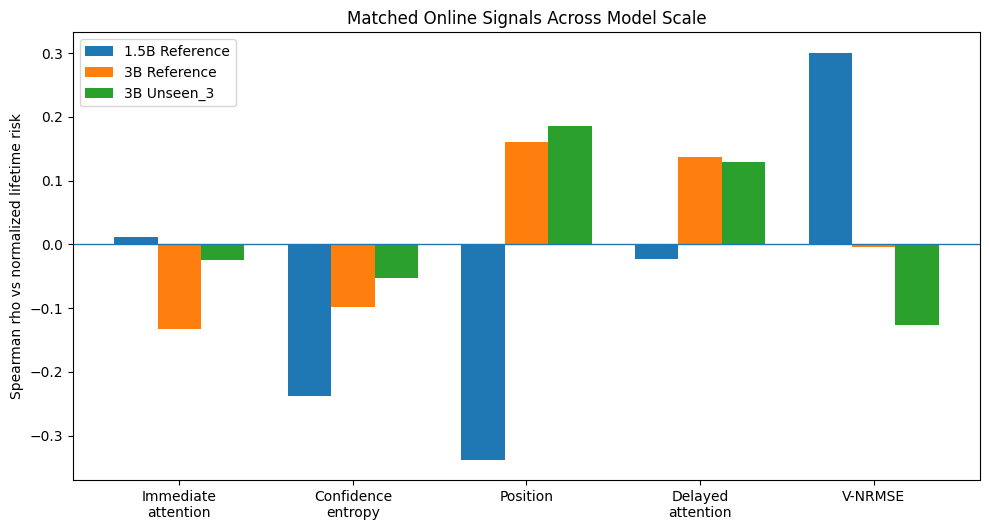

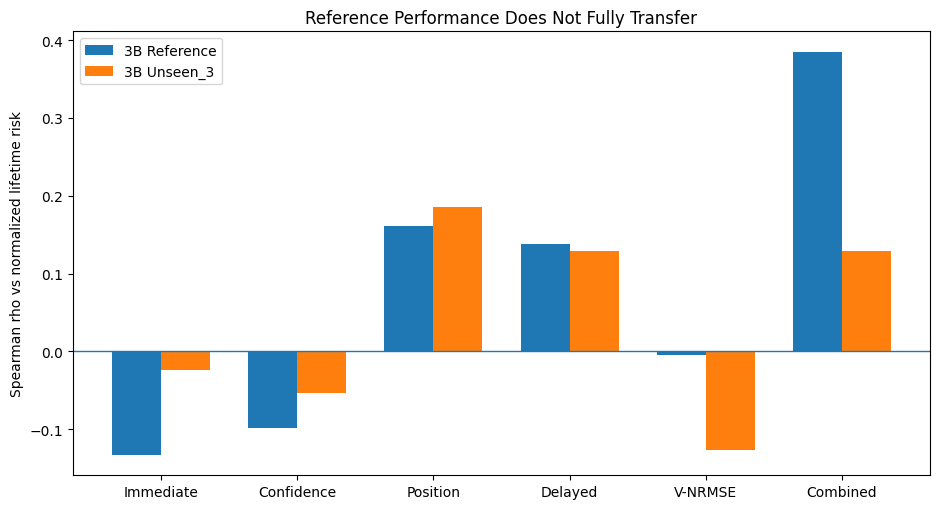

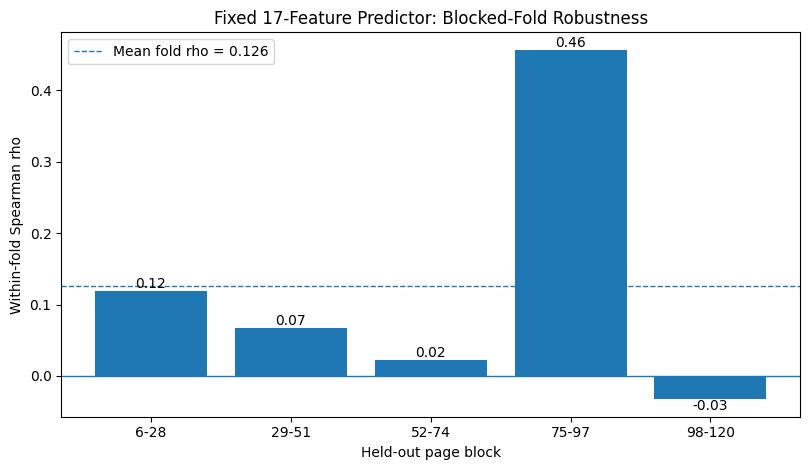

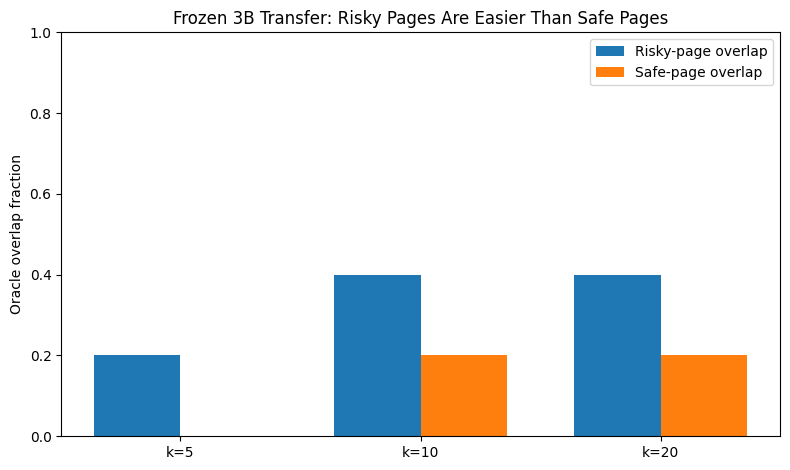



# Notebook 10 — Final Exploratory Conclusion

## Research question

Notebook 10 asked whether the online signals studied on
Qwen2.5-1.5B become more informative about page-level INT4
sensitivity when the experiment is repeated on Qwen2.5-3B.

This notebook is exploratory. Notebook 09 remains the frozen
confirmatory cross-model validation.

## Matched experimental setup

The 1.5B and 3B analyses use:

- the same 16-token logical pages;
- candidate Pages 6-120;
- a 32-token / two-page observation delay;
- the same affected-token normalized lifetime Delta-NLL target;
- matched attention, confidence, position, delayed-attention, and
  quantization-distortion features.

This removes the timing mismatch that affected the original
Notebook 06 analysis.

## Individual signals

Simple online signals do not generally become stronger at 3B.

The strongest individual matched 1.5B Reference correlation has
absolute Spearman rho approximately 0.406, while the strongest
individual 3B Reference corr

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# ============================================================
# Notebook 10 — FINAL EXPLORATORY SIGNAL ANALYSIS
# Cell 8
#
# FINAL CONSOLIDATION + EXPORT
#
# This cell:
#   - consolidates the matched 1.5B/3B signal study
#   - creates report-ready tables
#   - creates final figures
#   - records the final scientific conclusions
#   - exports Notebook 10 ZIP
#   - downloads the ZIP in Colab
#
# NO MORE EXPERIMENTS AFTER THIS CELL.
# ============================================================

from pathlib import Path
import json
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Final directories
# ============================================================

FINAL_DIR = (
    NB10_DIR
    / "final"
)

FIGURE_DIR = (
    FINAL_DIR
    / "figures"
)

FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 2. Final headline metrics
# ============================================================

fold_mean_rho = float(
    fold_results_df[
        "Spearman_Rho"
    ].mean()
)

fold_std_rho = float(
    fold_results_df[
        "Spearman_Rho"
    ].std(
        ddof=1
    )
)

fold_min_rho = float(
    fold_results_df[
        "Spearman_Rho"
    ].min()
)

fold_max_rho = float(
    fold_results_df[
        "Spearman_Rho"
    ].max()
)


# Fixed anchor values
def get_signal_rho(
    dataset,
    feature,
):

    row = (

        univariate_correlation_df[

            (
                univariate_correlation_df[
                    "Dataset"
                ]
                == dataset
            )

            &

            (
                univariate_correlation_df[
                    "Feature"
                ]
                == feature
            )

        ]
    )

    assert len(row) == 1

    return float(
        row.iloc[0][
            "Primary_Rho"
        ]
    )


delayed_1p5b_rho = get_signal_rho(
    "Qwen2.5-1.5B Reference",
    "DelayedAttn_Mean_Mean",
)

delayed_3b_ref_rho = get_signal_rho(
    "Qwen2.5-3B Reference",
    "DelayedAttn_Mean_Mean",
)

delayed_3b_unseen_rho = get_signal_rho(
    "Qwen2.5-3B Unseen_3",
    "DelayedAttn_Mean_Mean",
)


vnorm_1p5b_rho = get_signal_rho(
    "Qwen2.5-1.5B Reference",
    "V_NRMSE_Max",
)

vnorm_3b_ref_rho = get_signal_rho(
    "Qwen2.5-3B Reference",
    "V_NRMSE_Max",
)

vnorm_3b_unseen_rho = get_signal_rho(
    "Qwen2.5-3B Unseen_3",
    "V_NRMSE_Max",
)


# ============================================================
# 3. Final research-question table
# ============================================================

final_questions_df = pd.DataFrame([

    {
        "Question":
            (
                "Do simple online signals generally become "
                "more predictive at 3B?"
            ),

        "Answer":
            "No",

        "Evidence":
            (
                "Matched 1.5B max |rho| = 0.406; "
                "3B Reference max |rho| = 0.239. "
                "No 3B individual signal survives FDR."
            ),
    },

    {
        "Question":
            (
                "Does delayed attention become more useful "
                "at 3B?"
            ),

        "Answer":
            "Modestly",

        "Evidence":
            (
                f"DelayedAttn_Mean_Mean rho: "
                f"{delayed_1p5b_rho:+.3f} at 1.5B, "
                f"{delayed_3b_ref_rho:+.3f} on 3B Reference, "
                f"{delayed_3b_unseen_rho:+.3f} on 3B Unseen_3."
            ),
    },

    {
        "Question":
            (
                "Does V_NRMSE_Max remain a reliable "
                "intrinsic sensitivity signal at 3B?"
            ),

        "Answer":
            "No",

        "Evidence":
            (
                f"rho changes from "
                f"{vnorm_1p5b_rho:+.3f} at 1.5B to "
                f"{vnorm_3b_ref_rho:+.3f} on 3B Reference "
                f"and {vnorm_3b_unseen_rho:+.3f} on Unseen_3."
            ),
    },

    {
        "Question":
            (
                "Can the fixed 17-feature Gradient Boosting "
                "model learn useful Reference structure?"
            ),

        "Answer":
            "Yes, moderately",

        "Evidence":
            (
                f"Blocked pooled OOF rho = {oof_rho:+.3f}; "
                f"mean per-fold rho = {fold_mean_rho:+.3f}."
            ),
    },

    {
        "Question":
            (
                "Does the combined predictor transfer "
                "strongly to Unseen_3?"
            ),

        "Answer":
            "No",

        "Evidence":
            (
                f"Frozen transfer rho = {transfer_rho:+.3f}; "
                f"p = {transfer_p:.3f}."
            ),
    },

    {
        "Question":
            (
                "Has reliable safe-page prediction for "
                "selective INT4 been solved?"
            ),

        "Answer":
            "No",

        "Evidence":
            (
                "Frozen combined predictor recovers only "
                "2/10 oracle-safest pages on Unseen_3."
            ),
    },
])


print(
    "Final Notebook 10 research questions"
)

print(
    "------------------------------------"
)

display(
    final_questions_df
)


# ============================================================
# 4. Compact final signal table
# ============================================================

final_signal_rows = []


for feature in ANCHOR_FEATURES:

    final_signal_rows.append({

        "Signal":
            feature,

        "1.5B_Reference_Rho":
            get_signal_rho(
                "Qwen2.5-1.5B Reference",
                feature,
            ),

        "3B_Reference_Rho":
            get_signal_rho(
                "Qwen2.5-3B Reference",
                feature,
            ),

        "3B_Unseen3_Rho":
            get_signal_rho(
                "Qwen2.5-3B Unseen_3",
                feature,
            ),
    })


final_signal_rows.append({

    "Signal":
        "Fixed17_GradientBoosting",

    "1.5B_Reference_Rho":
        np.nan,

    "3B_Reference_Rho":
        float(
            oof_rho
        ),

    "3B_Unseen3_Rho":
        float(
            transfer_rho
        ),
})


final_signal_summary_df = pd.DataFrame(
    final_signal_rows
)


print()
print(
    "Final matched signal summary"
)

print(
    "----------------------------"
)


display(
    final_signal_summary_df
)


# ============================================================
# 5. Final model robustness table
# ============================================================

final_model_robustness_df = pd.DataFrame([

    {
        "Evaluation":
            "3B Reference pooled blocked OOF",

        "Normalized_Risk_Rho":
            oof_rho,

        "P_Value":
            oof_p,

        "Total_Risk_Rho":
            oof_total_rho,

        "MAE":
            oof_mae,

        "RMSE":
            oof_rmse,
    },

    {
        "Evaluation":
            "Mean contiguous fold",

        "Normalized_Risk_Rho":
            fold_mean_rho,

        "P_Value":
            np.nan,

        "Total_Risk_Rho":
            np.nan,

        "MAE":
            float(
                fold_results_df[
                    "MAE"
                ].mean()
            ),

        "RMSE":
            float(
                fold_results_df[
                    "RMSE"
                ].mean()
            ),
    },

    {
        "Evaluation":
            "3B Reference -> Unseen_3 frozen transfer",

        "Normalized_Risk_Rho":
            transfer_rho,

        "P_Value":
            transfer_p,

        "Total_Risk_Rho":
            transfer_total_rho,

        "MAE":
            transfer_mae,

        "RMSE":
            transfer_rmse,
    },
])


print()
print(
    "Final predictor robustness summary"
)

print(
    "----------------------------------"
)


display(
    final_model_robustness_df
)


# ============================================================
# 6. Figure 1:
# fixed anchors across scale / transfer
# ============================================================

plot_anchor_features = [

    "Attn_Self_LayerMax",

    "Conf_Entropy_Last",

    "Normalized_Position",

    "DelayedAttn_Mean_Mean",

    "V_NRMSE_Max",
]


x = np.arange(
    len(
        plot_anchor_features
    )
)

width = 0.25


vals_1p5b = [

    get_signal_rho(
        "Qwen2.5-1.5B Reference",
        f,
    )

    for f in plot_anchor_features
]


vals_3b_ref = [

    get_signal_rho(
        "Qwen2.5-3B Reference",
        f,
    )

    for f in plot_anchor_features
]


vals_3b_unseen = [

    get_signal_rho(
        "Qwen2.5-3B Unseen_3",
        f,
    )

    for f in plot_anchor_features
]


fig, ax = plt.subplots(
    figsize=(
        10.0,
        5.4,
    )
)


ax.bar(
    x - width,
    vals_1p5b,
    width,
    label="1.5B Reference",
)


ax.bar(
    x,
    vals_3b_ref,
    width,
    label="3B Reference",
)


ax.bar(
    x + width,
    vals_3b_unseen,
    width,
    label="3B Unseen_3",
)


ax.axhline(
    0,
    linewidth=1,
)


ax.set_xticks(
    x
)


ax.set_xticklabels(

    [
        "Immediate\nattention",
        "Confidence\nentropy",
        "Position",
        "Delayed\nattention",
        "V-NRMSE",
    ]
)


ax.set_ylabel(
    "Spearman rho vs normalized lifetime risk"
)


ax.set_title(
    "Matched Online Signals Across Model Scale"
)


ax.legend()


fig.tight_layout()


FIGURE_1_PATH = (

    FIGURE_DIR
    / "matched_signal_correlations.png"
)


fig.savefig(
    FIGURE_1_PATH,
    dpi=220,
    bbox_inches="tight",
)


plt.show()
plt.close(
    fig
)


# ============================================================
# 7. Figure 2:
# combined predictor vs simple anchors
# ============================================================

methods = [

    "Immediate",
    "Confidence",
    "Position",
    "Delayed",
    "V-NRMSE",
    "Combined",
]


reference_values = [

    get_signal_rho(
        "Qwen2.5-3B Reference",
        "Attn_Self_LayerMax",
    ),

    get_signal_rho(
        "Qwen2.5-3B Reference",
        "Conf_Entropy_Last",
    ),

    get_signal_rho(
        "Qwen2.5-3B Reference",
        "Normalized_Position",
    ),

    get_signal_rho(
        "Qwen2.5-3B Reference",
        "DelayedAttn_Mean_Mean",
    ),

    get_signal_rho(
        "Qwen2.5-3B Reference",
        "V_NRMSE_Max",
    ),

    oof_rho,
]


unseen_values = [

    get_signal_rho(
        "Qwen2.5-3B Unseen_3",
        "Attn_Self_LayerMax",
    ),

    get_signal_rho(
        "Qwen2.5-3B Unseen_3",
        "Conf_Entropy_Last",
    ),

    get_signal_rho(
        "Qwen2.5-3B Unseen_3",
        "Normalized_Position",
    ),

    get_signal_rho(
        "Qwen2.5-3B Unseen_3",
        "DelayedAttn_Mean_Mean",
    ),

    get_signal_rho(
        "Qwen2.5-3B Unseen_3",
        "V_NRMSE_Max",
    ),

    transfer_rho,
]


x = np.arange(
    len(
        methods
    )
)

width = 0.36


fig, ax = plt.subplots(
    figsize=(
        9.5,
        5.2,
    )
)


ax.bar(
    x - width / 2,
    reference_values,
    width,
    label="3B Reference",
)


ax.bar(
    x + width / 2,
    unseen_values,
    width,
    label="3B Unseen_3",
)


ax.axhline(
    0,
    linewidth=1,
)


ax.set_xticks(
    x
)


ax.set_xticklabels(
    methods
)


ax.set_ylabel(
    "Spearman rho vs normalized lifetime risk"
)


ax.set_title(
    "Reference Performance Does Not Fully Transfer"
)


ax.legend()


fig.tight_layout()


FIGURE_2_PATH = (

    FIGURE_DIR
    / "combined_predictor_transfer.png"
)


fig.savefig(
    FIGURE_2_PATH,
    dpi=220,
    bbox_inches="tight",
)


plt.show()
plt.close(
    fig
)


# ============================================================
# 8. Figure 3:
# fold-level robustness
# ============================================================

fig, ax = plt.subplots(
    figsize=(
        8.2,
        4.8,
    )
)


fold_labels = [

    f"{int(row.Page_Start)}-{int(row.Page_End)}"

    for _, row
    in fold_results_df.iterrows()
]


fold_rhos = (

    fold_results_df[
        "Spearman_Rho"
    ]
    .to_numpy()
)


bars = ax.bar(
    fold_labels,
    fold_rhos,
)


ax.axhline(
    0,
    linewidth=1,
)


ax.axhline(
    fold_mean_rho,
    linewidth=1,
    linestyle="--",
    label=(
        f"Mean fold rho = "
        f"{fold_mean_rho:.3f}"
    ),
)


ax.set_xlabel(
    "Held-out page block"
)


ax.set_ylabel(
    "Within-fold Spearman rho"
)


ax.set_title(
    "Fixed 17-Feature Predictor: Blocked-Fold Robustness"
)


ax.legend()


for bar, value in zip(
    bars,
    fold_rhos,
):

    ax.text(
        bar.get_x()
        + bar.get_width() / 2,

        value,

        f"{value:.2f}",

        ha="center",

        va=(
            "bottom"
            if value >= 0
            else "top"
        ),
    )


fig.tight_layout()


FIGURE_3_PATH = (

    FIGURE_DIR
    / "combined_predictor_fold_robustness.png"
)


fig.savefig(
    FIGURE_3_PATH,
    dpi=220,
    bbox_inches="tight",
)


plt.show()
plt.close(
    fig
)


# ============================================================
# 9. Figure 4:
# safe / risky overlap on frozen unseen transfer
# ============================================================

unseen_overlap = (

    combined_overlap_df[

        combined_overlap_df[
            "Dataset"
        ]
        ==
        "3B Unseen_3 Frozen Transfer"

    ]

    .sort_values(
        "K"
    )
)


x = np.arange(
    len(
        unseen_overlap
    )
)

width = 0.36


fig, ax = plt.subplots(
    figsize=(
        8.0,
        4.8,
    )
)


ax.bar(

    x - width / 2,

    unseen_overlap[
        "Risky_Overlap_Fraction"
    ],

    width,

    label="Risky-page overlap",
)


ax.bar(

    x + width / 2,

    unseen_overlap[
        "Safe_Overlap_Fraction"
    ],

    width,

    label="Safe-page overlap",
)


ax.set_xticks(
    x
)


ax.set_xticklabels(

    [
        f"k={int(k)}"

        for k in unseen_overlap[
            "K"
        ]
    ]
)


ax.set_ylim(
    0,
    1,
)


ax.set_ylabel(
    "Oracle overlap fraction"
)


ax.set_title(
    "Frozen 3B Transfer: Risky Pages Are Easier Than Safe Pages"
)


ax.legend()


fig.tight_layout()


FIGURE_4_PATH = (

    FIGURE_DIR
    / "unseen_safe_risky_overlap.png"
)


fig.savefig(
    FIGURE_4_PATH,
    dpi=220,
    bbox_inches="tight",
)


plt.show()
plt.close(
    fig
)


# ============================================================
# 10. Final scientific conclusion
# ============================================================

final_markdown = f"""
# Notebook 10 — Final Exploratory Conclusion

## Research question

Notebook 10 asked whether the online signals studied on
Qwen2.5-1.5B become more informative about page-level INT4
sensitivity when the experiment is repeated on Qwen2.5-3B.

This notebook is exploratory. Notebook 09 remains the frozen
confirmatory cross-model validation.

## Matched experimental setup

The 1.5B and 3B analyses use:

- the same 16-token logical pages;
- candidate Pages 6-120;
- a 32-token / two-page observation delay;
- the same affected-token normalized lifetime Delta-NLL target;
- matched attention, confidence, position, delayed-attention, and
  quantization-distortion features.

This removes the timing mismatch that affected the original
Notebook 06 analysis.

## Individual signals

Simple online signals do not generally become stronger at 3B.

The strongest individual matched 1.5B Reference correlation has
absolute Spearman rho approximately 0.406, while the strongest
individual 3B Reference correlation is approximately 0.239.

Eight 1.5B signals survive within-dataset FDR correction, whereas no
individual signal survives FDR correction on the 3B Reference or the
predeclared 3B Unseen_3 segment.

Delayed attention is the most interesting scale-dependent exception.

For `DelayedAttn_Mean_Mean`:

- 1.5B Reference: rho = {delayed_1p5b_rho:+.3f}
- 3B Reference: rho = {delayed_3b_ref_rho:+.3f}
- 3B Unseen_3: rho = {delayed_3b_unseen_rho:+.3f}

This suggests modest transferable information in short-term future
usage, but the effect remains weak.

`V_NRMSE_Max` does not transfer as a reliable intrinsic sensitivity
signal:

- 1.5B Reference: rho = {vnorm_1p5b_rho:+.3f}
- 3B Reference: rho = {vnorm_3b_ref_rho:+.3f}
- 3B Unseen_3: rho = {vnorm_3b_unseen_rho:+.3f}

## Fixed 17-feature combined predictor

A single predeclared GradientBoostingRegressor was evaluated with no
feature selection or hyperparameter search.

On the 3B Reference sequence, pooled blocked out-of-fold prediction
reaches

rho = {oof_rho:+.3f}

for normalized lifetime risk.

However, this pooled result is not uniformly robust across page
regions. The mean within-fold rho is only

rho = {fold_mean_rho:+.3f},

with a range from {fold_min_rho:+.3f} to {fold_max_rho:+.3f}.

After fitting on all Reference pages and transferring the model
unchanged to Unseen_3, normalized-risk correlation falls to

rho = {transfer_rho:+.3f}
(p = {transfer_p:.3f}).

The combined predictor therefore does not provide a strong transfer
advantage over the simple delayed-attention anchor.

## Safe-page identification

The practical mixed-precision problem requires finding pages that are
safe to demote to INT4.

On the frozen Unseen_3 transfer:

- top-10 risky-page overlap = 4/10;
- top-10 safe-page overlap = 2/10;
- top-20 risky-page overlap = 8/20;
- top-20 safe-page overlap = 4/20.

The predictor is therefore more useful for identifying risky pages
than for reliably identifying the safest pages.

## Final cross-notebook interpretation

Notebook 09 showed that Qwen2.5-3B is substantially more tolerant to
selective INT4 than Qwen2.5-1.5B.

Notebook 10 shows that this improvement should not be explained by
page sensitivity becoming easier to predict.

Instead, the evidence supports two distinct conclusions:

1. model scale materially affects robustness to aggressive KV-cache
   quantization;
2. reliable online safe-page prediction remains difficult.

The larger model reduces the cost of selection mistakes, but the
tested online signals do not eliminate those mistakes.

## Final practical recommendation

The strongest practical policy remains uniform INT8 KV-cache
quantization.

Across Qwen2.5-1.5B and Qwen2.5-3B it approximately halves analytical
KV-cache memory while producing very small quality degradation.

Selective per-vector INT4 remains scientifically promising because
oracle-selected subsets can perform extremely well, especially at
3B, but the present attention / confidence / recency / distortion
signals do not support a sufficiently reliable transferable demotion
controller.

## Implementation scope

All INT8/INT4 memory numbers in the project are analytical packed-cache
estimates.

The quality prototype quantizes and dequantizes values into the
standard FP16 DynamicCache rather than implementing custom packed
low-bit attention kernels.

No physical GPU-cache allocation, bandwidth reduction, generation
throughput, or runtime speedup claim is made.

Notebook 10 is the FINAL experimental notebook.
No Notebook 11 is planned.
"""


FINAL_MD_PATH = (

    FINAL_DIR
    / "notebook10_final_conclusion.md"
)


with open(
    FINAL_MD_PATH,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        final_markdown
    )


print()
print(
    final_markdown
)


# ============================================================
# 11. Final JSON
# ============================================================

final_json = {

    "notebook":
        "Notebook 10 — Final Exploratory Signal Analysis",

    "status":
        "COMPLETE",

    "analysis_type":
        "Exploratory",

    "main_question":
        (
            "Do online page-sensitivity signals become "
            "more informative at Qwen2.5-3B?"
        ),

    "answer":
        "Not generally",

    "key_results": {

        "individual_signals": {

            "max_abs_rho_1p5b_reference":
                0.406226,

            "max_abs_rho_3b_reference":
                0.239438,

            "fdr_significant_1p5b_reference":
                8,

            "fdr_significant_3b_reference":
                0,

            "fdr_significant_3b_unseen3":
                0,
        },

        "delayed_attention": {

            "1p5b_reference_rho":
                delayed_1p5b_rho,

            "3b_reference_rho":
                delayed_3b_ref_rho,

            "3b_unseen3_rho":
                delayed_3b_unseen_rho,
        },

        "v_nrmse_max": {

            "1p5b_reference_rho":
                vnorm_1p5b_rho,

            "3b_reference_rho":
                vnorm_3b_ref_rho,

            "3b_unseen3_rho":
                vnorm_3b_unseen_rho,
        },

        "fixed17_gradient_boosting": {

            "reference_pooled_oof_rho":
                float(
                    oof_rho
                ),

            "mean_fold_rho":
                fold_mean_rho,

            "std_fold_rho":
                fold_std_rho,

            "min_fold_rho":
                fold_min_rho,

            "max_fold_rho":
                fold_max_rho,

            "unseen3_transfer_rho":
                float(
                    transfer_rho
                ),

            "unseen3_transfer_p":
                float(
                    transfer_p
                ),

            "unseen3_total_risk_rho":
                float(
                    transfer_total_rho
                ),
        },

        "final_practical_recommendation":
            "Uniform INT8",
    },

    "cross_model_interpretation": {

        "3b_more_tolerant_to_selective_int4":
            True,

        "3b_page_sensitivity_easier_to_predict":
            False,

        "delayed_attention_modestly_promising":
            True,

        "combined_predictor_strong_transfer":
            False,

        "safe_page_prediction_solved":
            False,
    },

    "limitations": [

        "Only Qwen2.5-1.5B and Qwen2.5-3B were compared.",

        "Both models are from the same model family.",

        "Only one 3B Reference segment was used for development.",

        "Only one frozen 3B unseen segment had complete page-level lifetime oracle labels.",

        "Notebook 10 is exploratory rather than confirmatory.",

        "Gradient Boosting pooled OOF performance is heterogeneous across contiguous page folds.",

        "Analytical packed-cache memory is not physical low-bit GPU allocation.",

        "No low-bit attention kernel or runtime speedup was implemented.",
    ],
}


FINAL_JSON_PATH = (

    FINAL_DIR
    / "notebook10_final_conclusion.json"
)


with open(
    FINAL_JSON_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_json,
        f,
        indent=2,
    )


# ============================================================
# 12. Save report-ready tables
# ============================================================

FINAL_QUESTIONS_PATH = (

    FINAL_DIR
    / "final_research_questions.csv"
)


FINAL_SIGNALS_PATH = (

    FINAL_DIR
    / "final_signal_summary.csv"
)


FINAL_ROBUSTNESS_PATH = (

    FINAL_DIR
    / "final_predictor_robustness.csv"
)


FINAL_FOLDS_PATH = (

    FINAL_DIR
    / "final_blocked_fold_results.csv"
)


FINAL_OVERLAP_PATH = (

    FINAL_DIR
    / "final_unseen_oracle_overlap.csv"
)


FINAL_IMPORTANCE_PATH = (

    FINAL_DIR
    / "final_gradient_boosting_feature_importance.csv"
)


final_questions_df.to_csv(
    FINAL_QUESTIONS_PATH,
    index=False,
)


final_signal_summary_df.to_csv(
    FINAL_SIGNALS_PATH,
    index=False,
)


final_model_robustness_df.to_csv(
    FINAL_ROBUSTNESS_PATH,
    index=False,
)


fold_results_df.to_csv(
    FINAL_FOLDS_PATH,
    index=False,
)


unseen_overlap.to_csv(
    FINAL_OVERLAP_PATH,
    index=False,
)


feature_importance_df.to_csv(
    FINAL_IMPORTANCE_PATH,
    index=False,
)


# ============================================================
# 13. Write compact project-end note
# ============================================================

PROJECT_END_PATH = (

    FINAL_DIR
    / "EXPERIMENTAL_PHASE_COMPLETE.txt"
)


with open(
    PROJECT_END_PATH,
    "w",
    encoding="utf-8",
) as f:

    f.write(

        "Experimental phase complete.\n\n"

        "Final practical recommendation: "
        "uniform INT8 KV-cache quantization.\n\n"

        "Selective INT4 shows substantial oracle headroom, "
        "especially on Qwen2.5-3B, but reliable transferable "
        "safe-page prediction remains unresolved.\n\n"

        "Notebook 10 is the final experimental notebook.\n"

        "Next stages:\n"
        "1. Final research article\n"
        "2. 5-7 minute presentation\n"
    )


# ============================================================
# 14. Inventory
# ============================================================

all_files = sorted(

    p.relative_to(
        NB10_DIR
    )

    for p in NB10_DIR.rglob(
        "*"
    )

    if p.is_file()
)


print()
print(
    "=================================================="
)

print(
    "NOTEBOOK 10 ARTIFACT INVENTORY"
)

print(
    "=================================================="
)


for path in all_files:

    print(
        path
    )


# ============================================================
# 15. ZIP complete Notebook 10 results
# ============================================================

ZIP_BASE = (
    "notebook10_final_results"
)


zip_path_str = shutil.make_archive(

    ZIP_BASE,

    "zip",

    root_dir=str(
        NB10_DIR
    ),
)


ZIP_PATH = Path(
    zip_path_str
)


print()
print(
    "=================================================="
)

print(
    "FINAL EXPERIMENTAL CONCLUSION"
)

print(
    "=================================================="
)

print()

print(
    "1. Uniform INT8 remains the strongest "
    "practical recommendation."
)

print()

print(
    "2. Qwen2.5-3B is substantially more tolerant "
    "to selective INT4 than Qwen2.5-1.5B."
)

print()

print(
    "3. Model scale does NOT make page sensitivity "
    "generally easier to predict."
)

print()

print(
    f"4. Fixed17 Reference pooled OOF rho: "
    f"{oof_rho:+.3f}"
)

print(
    f"   Mean within-fold rho:              "
    f"{fold_mean_rho:+.3f}"
)

print(
    f"   Frozen Unseen_3 transfer rho:      "
    f"{transfer_rho:+.3f}"
)

print()

print(
    "5. Delayed attention contains modest transferable "
    "information, but safe-page selection remains weak."
)

print()

print(
    "6. Selective INT4 retains oracle headroom, "
    "not a validated deployable controller."
)

print()

print(
    "NO Notebook 11."
)

print(
    "The experimental phase is complete."
)

print()

print(
    f"Final Markdown: "
    f"{FINAL_MD_PATH}"
)

print(
    f"Final JSON:     "
    f"{FINAL_JSON_PATH}"
)

print(
    f"Final ZIP:      "
    f"{ZIP_PATH}"
)


# ============================================================
# 16. Download ZIP in Google Colab
# ============================================================

try:

    from google.colab import files


    print()
    print(
        "Starting ZIP download..."
    )


    files.download(
        str(
            ZIP_PATH
        )
    )


except ImportError:

    print()
    print(
        "Not running in Google Colab."
    )

    print(
        f"Download manually from: "
        f"{ZIP_PATH}"
    )